In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
from matplotlib.gridspec import GridSpec

In [36]:
# 初始设置
PREVIOUS_MAX_ROWS = pd.options.display.max_rows
pd.options.display.max_rows = 25
pd.options.display.max_columns = 20
pd.options.display.max_colwidth = 82
np.random.seed(12345)
plt.rc("figure", figsize=(10, 6))
np.set_printoptions(precision=4, suppress=True)

In [37]:
# 设置中文字体支持
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
house1_df = pd.read_csv("../data/house1.csv")
house2_df = pd.read_csv("../data/house2.csv")
house3_df = pd.read_csv("../data/house3.csv")
house4_df = pd.read_csv("../data/house5.csv")
house5_df = pd.read_csv("../data/house6.csv") 

In [39]:
# ======================= 数据清洗函数 =======================

In [40]:
def print_missing_stats(df, df_name):
    """打印缺失值统计"""
    total_rows = len(df)
    missing_stats = df.isna().sum()
    missing_percent = (missing_stats / total_rows * 100).round(2)
    
    print(f"\n{df_name} 缺失值统计:")
    print(f"总行数: {total_rows}")
    print("各列缺失情况:")
    print(pd.DataFrame({
        '缺失数量': missing_stats,
        '缺失比例(%)': missing_percent
    }))
    
    # 检查整个数据集是否有缺失
    if missing_stats.sum() > 0:
        print(f"\n⚠️ 警告: {df_name} 包含缺失值!")
    else:
        print(f"\n✅ {df_name} 无缺失值")

def clean_energy_data(df, df_name):
    """家庭能耗数据清洗流程"""
    # 1. 处理时间列缺失
    df_clean = df.dropna(subset=['Time'])
    
    # 2. 数值列缺失分析
    num_cols = ['Aggregate', 'dishwasher', 'washingmachine']
    missing_count = df_clean[num_cols].isna().sum()

    print(f"\n{df_name} 缺失值统计:")
    print(missing_count)
    print(f"总缺失行: {missing_count.sum()}/{len(df_clean)}({missing_count.sum()/len(df_clean):.2%})")
    
    # 3. 根据缺失量选择处理方式
    if missing_count.sum() == 0:
        print("无缺失值，无需处理")
        return df_clean
    
    elif missing_count.sum() < len(df_clean) * 0.01:  # 缺失<1%
        print("少量缺失，直接删除")
        return df_clean.dropna(subset=num_cols)
    
    else:
        print("使用前向填充处理能耗数据")
        # 确保时间排序
        df_clean = df_clean.sort_values('Time')
        
        # 分组填充
        df_clean[num_cols] = df_clean.groupby(df_clean['Time'].dt.date)[num_cols].transform(
            lambda x: x.fillna(method='ffill'))
        
        return df_clean.dropna(subset=num_cols)

def duplicates_data(df, df_name):
    """检测重复数据"""
    duplicates = df.duplicated().sum()
    time_dups = df.duplicated(subset=['Time']).sum()
    print(f"{df_name}: 重复行数量: {duplicates}   重复时间戳: {time_dups}")

def remove_negative_power(df, df_name, cols=None):
    """处理负值数据"""
    if cols is None:
        cols = ['Aggregate', 'dishwasher', 'washingmachine']
    
    neg_report = {}
    for col in cols:
        neg_count = (df[col] < 0).sum()
        df.loc[df[col] < 0, col] = 0
        neg_report[col] = {'count': neg_count}
    
    print(f"\n{df_name} 负值处理:")
    for col, stats in neg_report.items():
        print(f"  {col}: 替换 {stats['count']} 个负值 ")
    return df, neg_report


In [41]:
# ======================= 分析函数 =======================

In [42]:
def calculate_hourly_energy(df, house_name):
    """计算每小时能耗（考虑实际时间间隔）"""
    df = df.copy()
    # 确保时间列是datetime类型
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    df = df.sort_values('Time')
    
    # 计算时间间隔（单位：小时）
    df['TimeDelta'] = df['Time'].diff().dt.total_seconds() / 3600
    df.loc[df.index[0], 'TimeDelta'] = df.loc[df.index[1], 'TimeDelta'] if len(df) > 1 else 1/60
    
    # 计算能耗（kWh）
    df['Total_Energy'] = df['Aggregate'] * df['TimeDelta'] / 1000
    df['Dishwasher_Energy'] = df['dishwasher'] * df['TimeDelta'] / 1000
    df['WashingMachine_Energy'] = df['washingmachine'] * df['TimeDelta'] / 1000
    
    # 提取小时和星期信息
    df['Hour'] = df['Time'].dt.hour
    df['DayOfWeek'] = df['Time'].dt.dayofweek  # Monday=0, Sunday=6
    df['IsWeekend'] = df['DayOfWeek'] >= 5  # 周末标记
    
    # 按小时分组统计
    hourly_energy = df.groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum',
        'TimeDelta': 'sum'  # 总时间长度
    }).reset_index()
    
    # 计算其他设备能耗
    hourly_energy['Other_Energy'] = (
        hourly_energy['Total_Energy'] - 
        hourly_energy['Dishwasher_Energy'] - 
        hourly_energy['WashingMachine_Energy']
    )
    
    # 计算平均功率
    hourly_energy['Avg_Power'] = hourly_energy['Total_Energy'] / hourly_energy['TimeDelta'] * 1000
    
    # 按工作日/周末分组统计
    weekday_energy = df[df['IsWeekend'] == False].groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum'
    }).reset_index()
    
    weekend_energy = df[df['IsWeekend'] == True].groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum'
    }).reset_index()
    
    print(f"\n{house_name} 每小时能耗统计:")
    print(hourly_energy.head(24))
    
    return hourly_energy, weekday_energy, weekend_energy

def analyze_appliance_activity(df, house_name):
    """分析电器活动模式"""
    df = df.copy()
    # 确保时间列是datetime类型
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    
    df['Hour'] = df['Time'].dt.hour
    df['DayOfWeek'] = df['Time'].dt.dayofweek
    df['IsWeekend'] = df['DayOfWeek'] >= 5
    
    # 统计每小时活动次数
    activity_stats = df.groupby('Hour').agg({
        'dishwasher': lambda x: (x > 0).sum(),
        'washingmachine': lambda x: (x > 0).sum(),
        'Time': 'count'  # 活动记录数
    }).reset_index()
    
    activity_stats.columns = ['Hour', 'Dishwasher_Activity', 'WashingMachine_Activity', 'Total_Records']
    
    print(f"\n{house_name} 电器活动统计:")
    print(activity_stats.head(24))
    return activity_stats

def plot_combined_analysis(energy_df, activity_df, house_name):
    """综合可视化能耗和活动模式"""
    fig, ax1 = plt.subplots(figsize=(14, 8))
    
    # 绘制能耗曲线 (左轴)
    ax1.plot(energy_df['Hour'], energy_df['Total_Energy'], label='总能耗', color='#d62728', linewidth=2.5, marker='o')
    ax1.plot(energy_df['Hour'], energy_df['Dishwasher_Energy'], label='洗碗机能耗', color='#1f77b4', linewidth=2, marker='s')
    ax1.plot(energy_df['Hour'], energy_df['WashingMachine_Energy'], label='洗衣机能耗', color='#ff7f0e', linewidth=2, marker='^')
    ax1.set_xlabel('小时', fontsize=12)
    ax1.set_ylabel('能耗 (kWh)', fontsize=12)
    ax1.set_xticks(range(0, 24))
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax1.legend(loc='upper left')
    
    # 创建第二个y轴（活动频率）
    ax2 = ax1.twinx()
    max_activity = (activity_df['Dishwasher_Activity'] + activity_df['WashingMachine_Activity']).max()
    
    # 绘制活动柱状图
    ax2.bar(activity_df['Hour'], activity_df['Dishwasher_Activity'], alpha=0.3, color='#1f77b4', width=0.4, label='洗碗机活动')
    ax2.bar(activity_df['Hour'], activity_df['WashingMachine_Activity'], alpha=0.3, color='#ff7f0e', width=0.4, label='洗衣机活动',
           bottom=activity_df['Dishwasher_Activity'])
    ax2.set_ylabel('活动次数', fontsize=12)
    ax2.set_ylim(0, max_activity * 1.2)  # 设置y轴范围
    
    # 设置标题
    plt.title(f'{house_name} - 能耗与电器活动综合分析', fontsize=16)
    
    # 合并图例
    lines, labels = ax1.get_legend_handles_labels()
    bars, bar_labels = ax2.get_legend_handles_labels()
    ax2.legend(lines + bars, labels + bar_labels, loc='upper right')
    
    plt.tight_layout()
    plt.show()

def plot_weekday_weekend_comparison(weekday_energy, weekend_energy, house_name):
    """绘制工作日与周末能耗对比"""
    plt.figure(figsize=(14, 8))
    
    # 绘制工作日能耗
    plt.plot(weekday_energy['Hour'], weekday_energy['Total_Energy'], 
             label='工作日总能耗', color='#1f77b4', linewidth=2.5, marker='o')
    plt.plot(weekday_energy['Hour'], weekday_energy['Dishwasher_Energy'], 
             label='工作日洗碗机', color='#1f77b4', linewidth=2, marker='s', linestyle='--')
    plt.plot(weekday_energy['Hour'], weekday_energy['WashingMachine_Energy'], 
             label='工作日洗衣机', color='#1f77b4', linewidth=2, marker='^', linestyle=':')
    
    # 绘制周末能耗
    plt.plot(weekend_energy['Hour'], weekend_energy['Total_Energy'], 
             label='周末总能耗', color='#ff7f0e', linewidth=2.5, marker='o')
    plt.plot(weekend_energy['Hour'], weekend_energy['Dishwasher_Energy'], 
             label='周末洗碗机', color='#ff7f0e', linewidth=2, marker='s', linestyle='--')
    plt.plot(weekend_energy['Hour'], weekend_energy['WashingMachine_Energy'], 
             label='周末洗衣机', color='#ff7f0e', linewidth=2, marker='^', linestyle=':')
    
    # 设置图表属性
    plt.title(f'{house_name} - 工作日与周末能耗对比', fontsize=16)
    plt.xlabel('小时', fontsize=12)
    plt.ylabel('能耗 (kWh)', fontsize=12)
    plt.xticks(range(0, 24))
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    
    # 添加峰值时段标记
    peak_hours = [7, 8, 9, 18, 19, 20, 21]  # 常见峰值时段
    for hour in peak_hours:
        plt.axvspan(hour, hour+1, alpha=0.1, color='red')
    
    plt.tight_layout()
    plt.show()

def plot_hourly_usage(hourly_results):
    """绘制所有房屋的小时用电模式"""
    # 创建大图表
    fig, axes = plt.subplots(3, 2, figsize=(18, 20))
    axes = axes.flatten()
    
    # 为每个房屋创建子图
    for i, (house_name, data) in enumerate(hourly_results.items()):
        if i >= len(axes):  # 防止超出子图数量
            break
            
        energy_df, _, _ = data  # 解包数据
        ax = axes[i]
        
        # 绘制平均功率曲线
        ax.plot(
            energy_df['Hour'], 
            energy_df['Avg_Power'], 
            label='总功率', 
            color='#d62728', 
            linewidth=2.5,
            marker='o'
        )
        ax.plot(
            energy_df['Hour'], 
            energy_df['Dishwasher_Energy'] / energy_df['TimeDelta'] * 1000, 
            label='洗碗机', 
            color='#1f77b4', 
            linewidth=2,
            marker='s'
        )
        ax.plot(
            energy_df['Hour'], 
            energy_df['WashingMachine_Energy'] / energy_df['TimeDelta'] * 1000, 
            label='洗衣机', 
            color='#ff7f0e', 
            linewidth=2,
            marker='^'
        )
        
        # 设置子图属性
        ax.set_title(f'{house_name} - 每小时平均功率', fontsize=14)
        ax.set_xlabel('小时', fontsize=12)
        ax.set_ylabel('平均功率 (W)', fontsize=12)
        ax.set_xticks(range(0, 24))
        ax.grid(True, linestyle='--', alpha=0.7)
        ax.legend()
        
        # 添加峰值时段标记
        peak_hours = [7, 8, 9, 18, 19, 20, 21]  # 常见峰值时段
        for hour in peak_hours:
            ax.axvspan(hour, hour+1, alpha=0.1, color='red')
    
    # 添加大标题
    fig.suptitle('不同家庭每小时用电模式对比', fontsize=20, y=0.95)
    
    # 调整布局
    plt.tight_layout()
    plt.subplots_adjust(top=0.92)
    plt.show()

def plot_hourly_energy_stacked(hourly_results):
    """绘制所有房屋的小时能耗堆叠图"""
    fig, ax = plt.subplots(figsize=(16, 10))
    
    # 准备数据
    houses = list(hourly_results.keys())
    hours = range(0, 24)
    
    # 创建矩阵存储总能耗
    total_energy_matrix = np.zeros((24, len(houses)))
    
    # 创建颜色映射
    colors = plt.cm.tab10(np.linspace(0, 1, len(houses)))
    
    # 绘制堆叠柱状图
    bottom = np.zeros(len(hours))
    
    for i, (house, data) in enumerate(hourly_results.items()):
        energy_df, _, _ = data  # 解包数据
        # 确保数据按小时排序
        energy_df = energy_df.sort_values('Hour')
        
        # 如果数据不完整，填充0
        if len(energy_df) < 24:
            full_hours = pd.DataFrame({'Hour': range(24)})
            energy_df = pd.merge(full_hours, energy_df, on='Hour', how='left').fillna(0)
        
        house_energy = energy_df['Total_Energy'].values
        
        # 绘制每个房屋的能耗
        ax.bar(
            hours,
            house_energy,
            bottom=bottom,
            label=house,
            color=colors[i],
            alpha=0.8
        )
        
        # 添加能耗标签
        for j, hour in enumerate(hours):
            if house_energy[j] > 0.1:  # 只显示大于0.1kWh的标签
                ax.text(
                    hour,
                    bottom[j] + house_energy[j]/2,
                    f'{house_energy[j]:.1f}',
                    ha='center',
                    va='center',
                    fontsize=8,
                    color='white' if i < 3 else 'black'
                )
        
        # 更新底部位置
        bottom += house_energy
        # 保存总能耗矩阵
        total_energy_matrix[:, i] = house_energy
    
    # 设置图表属性
    ax.set_title('所有家庭每小时总能耗对比', fontsize=18)
    ax.set_xlabel('小时', fontsize=14)
    ax.set_ylabel('总能耗 (kWh)', fontsize=14)
    ax.set_xticks(range(0, 24))
    ax.legend(title='家庭', loc='upper left')
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # 添加峰值时段标记
    for hour in [7, 8, 9, 18, 19, 20, 21]:
        ax.axvspan(hour-0.5, hour+0.5, alpha=0.1, color='red', zorder=0)
    
    plt.tight_layout()
    plt.show()
    
    return total_energy_matrix

def plot_hourly_heatmap(hourly_results):
    """绘制所有家庭每小时用电热力图"""
    # 创建数据矩阵
    heatmap_data = pd.DataFrame()
    
    for house_name, data in hourly_results.items():
        energy_df, _, _ = data  # 解包数据
        # 确保数据按小时排序
        energy_df = energy_df.sort_values('Hour')
        
        # 如果数据不完整，填充0
        if len(energy_df) < 24:
            full_hours = pd.DataFrame({'Hour': range(24)})
            energy_df = pd.merge(full_hours, energy_df, on='Hour', how='left').fillna(0)
        
        heatmap_data[house_name] = energy_df['Total_Energy'].values
    
    heatmap_data.index = range(0, 24)
    
    # 创建热力图
    plt.figure(figsize=(14, 10))
    sns.heatmap(
        heatmap_data.T,  # 转置矩阵：行是家庭，列是小时
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        annot_kws={"size": 9}
    )
    
    # 设置图表属性
    plt.title('所有家庭每小时能耗热力图 (kWh)', fontsize=16, pad=20)
    plt.xlabel('小时', fontsize=12)
    plt.ylabel('家庭', fontsize=12)
    
    # 添加峰值时段标记
    for hour in [7, 8, 9, 18, 19, 20, 21]:
        plt.axvline(x=hour+0.5, color='red', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

def plot_appliance_usage_timing(hourly_results):
    """绘制电器使用时段分布"""
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # 准备数据
    hours = range(0, 24)
    
    # 创建洗碗机使用矩阵
    dishwasher_data = pd.DataFrame()
    # 创建洗衣机使用矩阵
    washingmachine_data = pd.DataFrame()
    
    for house_name, data in hourly_results.items():
        energy_df, _, _ = data  # 解包数据
        # 确保数据按小时排序
        energy_df = energy_df.sort_values('Hour')
        
        # 计算平均功率
        dishwasher_avg_power = energy_df['Dishwasher_Energy'] / energy_df['TimeDelta'] * 1000
        washingmachine_avg_power = energy_df['WashingMachine_Energy'] / energy_df['TimeDelta'] * 1000
        
        # 如果数据不完整，填充0
        if len(energy_df) < 24:
            full_hours = pd.DataFrame({'Hour': range(24)})
            dishwasher_avg_power = pd.merge(full_hours, pd.DataFrame({'Hour': energy_df['Hour'], 'Power': dishwasher_avg_power}), 
                                         on='Hour', how='left').fillna(0)['Power']
            washingmachine_avg_power = pd.merge(full_hours, pd.DataFrame({'Hour': energy_df['Hour'], 'Power': washingmachine_avg_power}), 
                                         on='Hour', how='left').fillna(0)['Power']
        
        dishwasher_data[house_name] = dishwasher_avg_power.values
        washingmachine_data[house_name] = washingmachine_avg_power.values
    
    # 绘制洗碗机使用情况
    for house in dishwasher_data.columns:
        axes[0].plot(
            hours,
            dishwasher_data[house],
            label=house,
            linewidth=2,
            marker='o'
        )
    
    axes[0].set_title('洗碗机每小时平均功率', fontsize=14)
    axes[0].set_xlabel('小时', fontsize=12)
    axes[0].set_ylabel('平均功率 (W)', fontsize=12)
    axes[0].set_xticks(range(0, 24))
    axes[0].grid(True, linestyle='--', alpha=0.7)
    axes[0].legend()
    
    # 标记高峰时段
    for hour in [18, 19, 20, 21]:
        axes[0].axvspan(hour, hour+1, alpha=0.1, color='red')
    
    # 绘制洗衣机使用情况
    for house in washingmachine_data.columns:
        axes[1].plot(
            hours,
            washingmachine_data[house],
            label=house,
            linewidth=2,
            marker='s'
        )
    
    axes[1].set_title('洗衣机每小时平均功率', fontsize=14)
    axes[1].set_xlabel('小时', fontsize=12)
    axes[1].set_ylabel('平均功率 (W)', fontsize=12)
    axes[1].set_xticks(range(0, 24))
    axes[1].grid(True, linestyle='--', alpha=0.7)
    axes[1].legend()
    
    # 标记高峰时段
    for hour in [8, 9, 10, 18, 19]:
        axes[1].axvspan(hour, hour+1, alpha=0.1, color='red')
    
    # 添加大标题
    fig.suptitle('电器使用时段分布', fontsize=18, y=0.98)
    
    plt.tight_layout()
    plt.show()

In [43]:
def plot_weekday_weekend_heatmap(weekday_energy_all, weekend_energy_all):
    """绘制所有家庭工作日和周末能耗热力图"""
    # 创建数据矩阵
    weekday_heatmap_data = pd.DataFrame()
    weekend_heatmap_data = pd.DataFrame()
    
    # 准备数据
    for house_name in weekday_energy_all.keys():
        # 工作日数据
        weekday_df = weekday_energy_all[house_name].sort_values('Hour')
        if len(weekday_df) < 24:
            full_hours = pd.DataFrame({'Hour': range(24)})
            weekday_df = pd.merge(full_hours, weekday_df, on='Hour', how='left').fillna(0)
        weekday_heatmap_data[house_name] = weekday_df['Total_Energy'].values
        
        # 周末数据
        weekend_df = weekend_energy_all[house_name].sort_values('Hour')
        if len(weekend_df) < 24:
            full_hours = pd.DataFrame({'Hour': range(24)})
            weekend_df = pd.merge(full_hours, weekend_df, on='Hour', how='left').fillna(0)
        weekend_heatmap_data[house_name] = weekend_df['Total_Energy'].values
    
    # 设置索引
    weekday_heatmap_data.index = range(0, 24)
    weekend_heatmap_data.index = range(0, 24)
    
    # 创建热力图
    fig, axes = plt.subplots(1, 2, figsize=(24, 10))
    
    # 工作日热力图
    sns.heatmap(
        weekday_heatmap_data.T,  # 转置矩阵：行是家庭，列是小时
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        annot_kws={"size": 9},
        ax=axes[0]
    )
    axes[0].set_title('所有家庭工作日每小时能耗热力图 (kWh)', fontsize=16, pad=20)
    axes[0].set_xlabel('小时', fontsize=12)
    axes[0].set_ylabel('家庭', fontsize=12)
    
    # 周末热力图
    sns.heatmap(
        weekend_heatmap_data.T,  # 转置矩阵：行是家庭，列是小时
        annot=True,
        fmt=".1f",
        cmap="YlOrRd",
        linewidths=0.5,
        annot_kws={"size": 9},
        ax=axes[1]
    )
    axes[1].set_title('所有家庭周末每小时能耗热力图 (kWh)', fontsize=16, pad=20)
    axes[1].set_xlabel('小时', fontsize=12)
    axes[1].set_ylabel('家庭', fontsize=12)
    
    # 添加峰值时段标记
    peak_hours = [7, 8, 9, 18, 19, 20, 21]
    for hour in peak_hours:
        axes[0].axvline(x=hour+0.5, color='red', linestyle='--', alpha=0.7)
        axes[1].axvline(x=hour+0.5, color='red', linestyle='--', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

In [44]:
# ======================= 主处理流程 =======================

In [45]:
# 1. 缺失值分析
datasets = {
    "House 1": house1_df,
    "House 2": house2_df,
    "House 3": house3_df,
    "House 4": house4_df,
    "House 5": house5_df
}

for name, df in datasets.items():
    print_missing_stats(df, name)


House 1 缺失值统计:
总行数: 746645
各列缺失情况:
                缺失数量  缺失比例(%)
Time               0      0.0
Aggregate          0      0.0
dishwasher         0      0.0
washingmachine     0      0.0

✅ House 1 无缺失值

House 2 缺失值统计:
总行数: 485951
各列缺失情况:
                缺失数量  缺失比例(%)
Time               0      0.0
Aggregate          0      0.0
dishwasher         0      0.0
washingmachine     0      0.0

✅ House 2 无缺失值

House 3 缺失值统计:
总行数: 790776
各列缺失情况:
                缺失数量  缺失比例(%)
Time               0      0.0
Aggregate          0      0.0
dishwasher         0      0.0
washingmachine     0      0.0

✅ House 3 无缺失值

House 4 缺失值统计:
总行数: 777437
各列缺失情况:
                缺失数量  缺失比例(%)
Time               0      0.0
Aggregate          0      0.0
dishwasher         0      0.0
washingmachine     0      0.0

✅ House 4 无缺失值

House 5 缺失值统计:
总行数: 883924
各列缺失情况:
                缺失数量  缺失比例(%)
Time               0      0.0
Aggregate          0      0.0
dishwasher         0      0.0
washingmachine     0      0.0

✅ Hou

In [46]:
# 2. 数据清洗流程
cleaned_dfs = {}
for i, (name, df) in enumerate(datasets.items(), 1):
    print(f"\n============ 处理 {name} ============")
    cleaned_df = clean_energy_data(df, name)
    duplicates_data(cleaned_df, name)
    cleaned_df, _ = remove_negative_power(cleaned_df, name)
    cleaned_dfs[f"House{i}"] = cleaned_df


============ 处理 House 1 ============

House 1 缺失值统计:
Aggregate         0
dishwasher        0
washingmachine    0
dtype: int64
总缺失行: 0/746645(0.00%)
无缺失值，无需处理
House 1: 重复行数量: 0   重复时间戳: 0

House 1 负值处理:
  Aggregate: 替换 0 个负值 
  dishwasher: 替换 0 个负值 
  washingmachine: 替换 0 个负值 

============ 处理 House 2 ============

House 2 缺失值统计:
Aggregate         0
dishwasher        0
washingmachine    0
dtype: int64
总缺失行: 0/485951(0.00%)
无缺失值，无需处理
House 2: 重复行数量: 0   重复时间戳: 0

House 2 负值处理:
  Aggregate: 替换 0 个负值 
  dishwasher: 替换 0 个负值 
  washingmachine: 替换 0 个负值 

============ 处理 House 3 ============

House 3 缺失值统计:
Aggregate         0
dishwasher        0
washingmachine    0
dtype: int64
总缺失行: 0/790776(0.00%)
无缺失值，无需处理
House 3: 重复行数量: 0   重复时间戳: 0

House 3 负值处理:
  Aggregate: 替换 0 个负值 
  dishwasher: 替换 0 个负值 
  washingmachine: 替换 0 个负值 

============ 处理 House 4 ============

House 4 缺失值统计:
Aggregate         0
dishwasher        0
washingmachine    0
dtype: int64
总缺失行: 0/777437(0.00%)
无缺失值，无需处理
House 4


======= 小时分析 =======

======= 分析 House1 小时能耗和电器活动 =======

House1 每小时能耗统计:
    Hour  Total_Energy  Dishwasher_Energy  WashingMachine_Energy  TimeDelta  \
0      0     36.022186           0.000000               0.000020  60.989444   
1      1     48.238969           0.000000               0.000000  60.004722   
2      2     48.205273           0.000427               0.000000  59.980000   
3      3     49.079609           1.505794               0.000000  60.019167   
4      4     52.415128           4.220169               0.648186  59.991944   
5      5     44.605407           5.288559               1.623107  60.002500   
6      6     25.762914           0.300944               2.065569  60.011111   
7      7     27.155614           0.000000               0.108137  59.954167   
8      8     28.737159           0.000000               0.000004  59.811389   
9      9     31.415852           0.390533               0.014753  60.061944   
10    10     39.985040           2.670149              

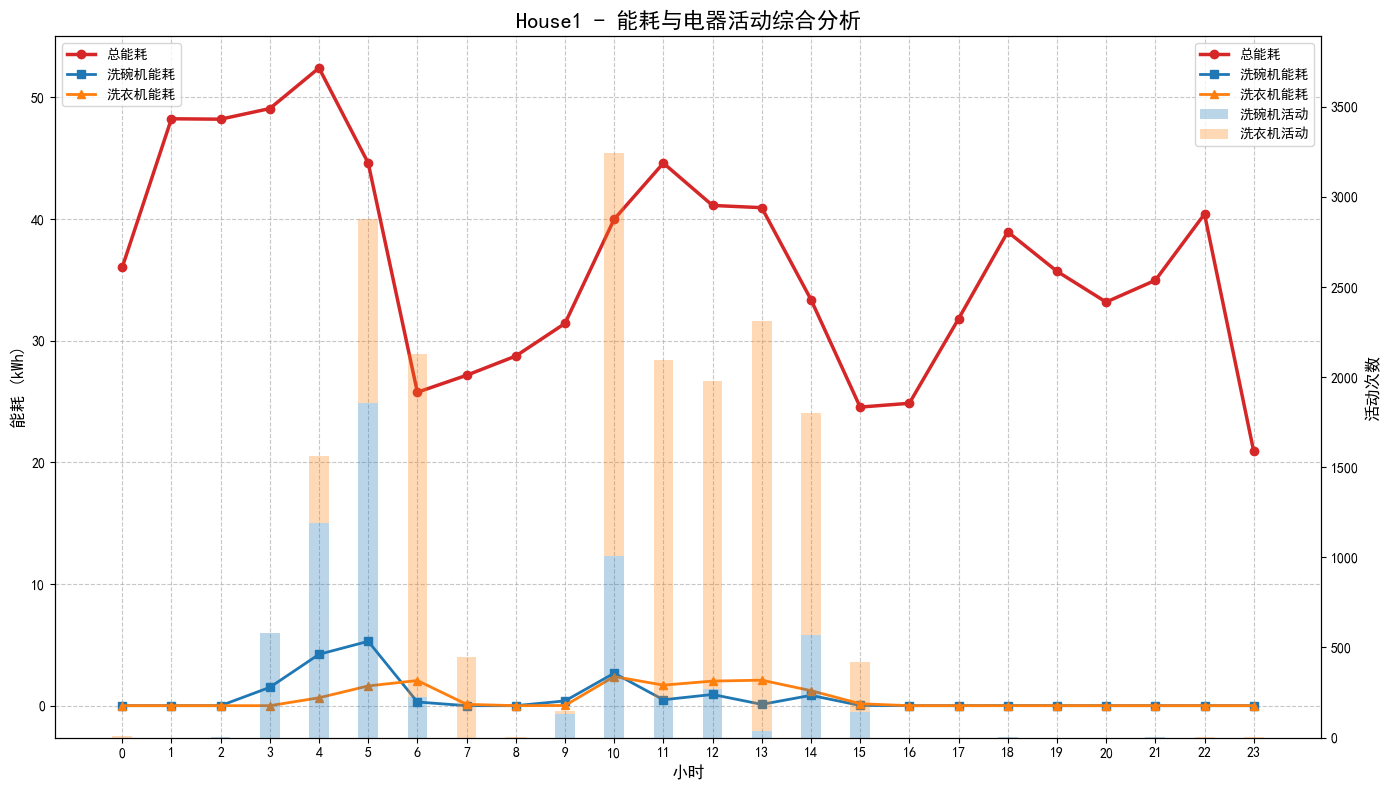


======= 分析 House2 小时能耗和电器活动 =======

House2 每小时能耗统计:
    Hour  Total_Energy  Dishwasher_Energy  WashingMachine_Energy  TimeDelta  \
0      0      4.824626           0.342003               0.000000  38.273056   
1      1      4.066627           0.000644               0.000000  37.998889   
2      2      4.017809           0.000000               0.000000  37.856111   
3      3      4.012774           0.000000               0.000000  38.121389   
4      4      4.120626           0.001564               0.000000  38.031667   
5      5      4.211537           0.000000               0.000000  37.989444   
6      6     14.935385           0.286160               0.000000  38.007222   
7      7     51.427909           1.954723               1.877157  37.996389   
8      8     21.750701           2.084518               2.107090  37.994167   
9      9     13.762013           1.946178               1.779257  38.001667   
10    10      6.651070           0.947194               0.160225  38.003611  

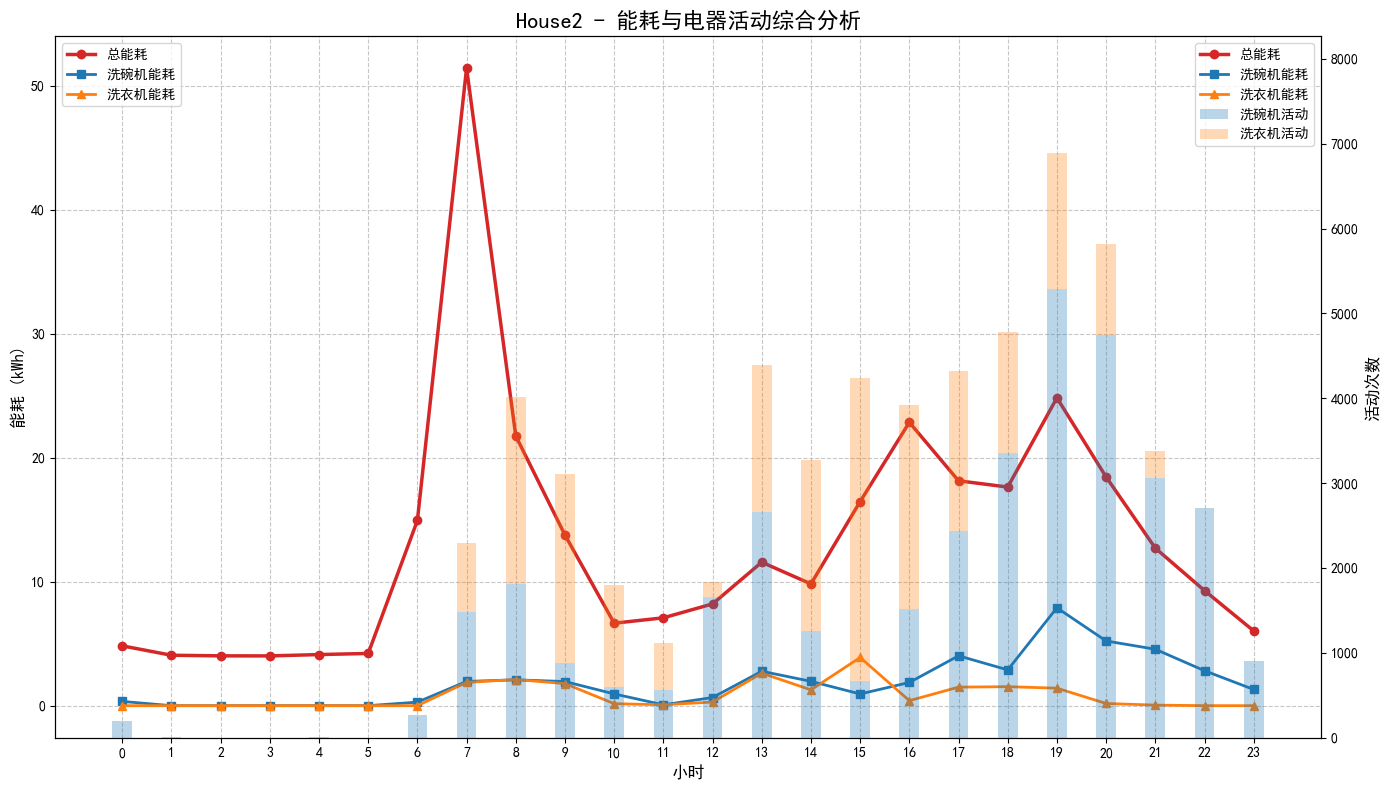


======= 分析 House3 小时能耗和电器活动 =======

House3 每小时能耗统计:
    Hour  Total_Energy  Dishwasher_Energy  WashingMachine_Energy   TimeDelta  \
0      0     13.858433           0.001000               0.000604   58.994444   
1      1     13.335875           0.645243               0.000000   57.994722   
2      2     13.192427           0.772925               0.000000   58.002222   
3      3     12.564729           0.002000               0.000000   57.995833   
4      4     13.874987           0.002000               0.470183   58.002500   
5      5     13.396615           0.002000               0.021860   57.993611   
6      6     22.274339           0.001000               0.386179   58.005000   
7      7     49.516962           1.571451               0.546318   58.003056   
8      8     77.852348           5.820829               5.125888  104.671667   
9      9     39.832006           9.967455               4.689281   59.011667   
10    10     41.896986           6.702040               5.185498  

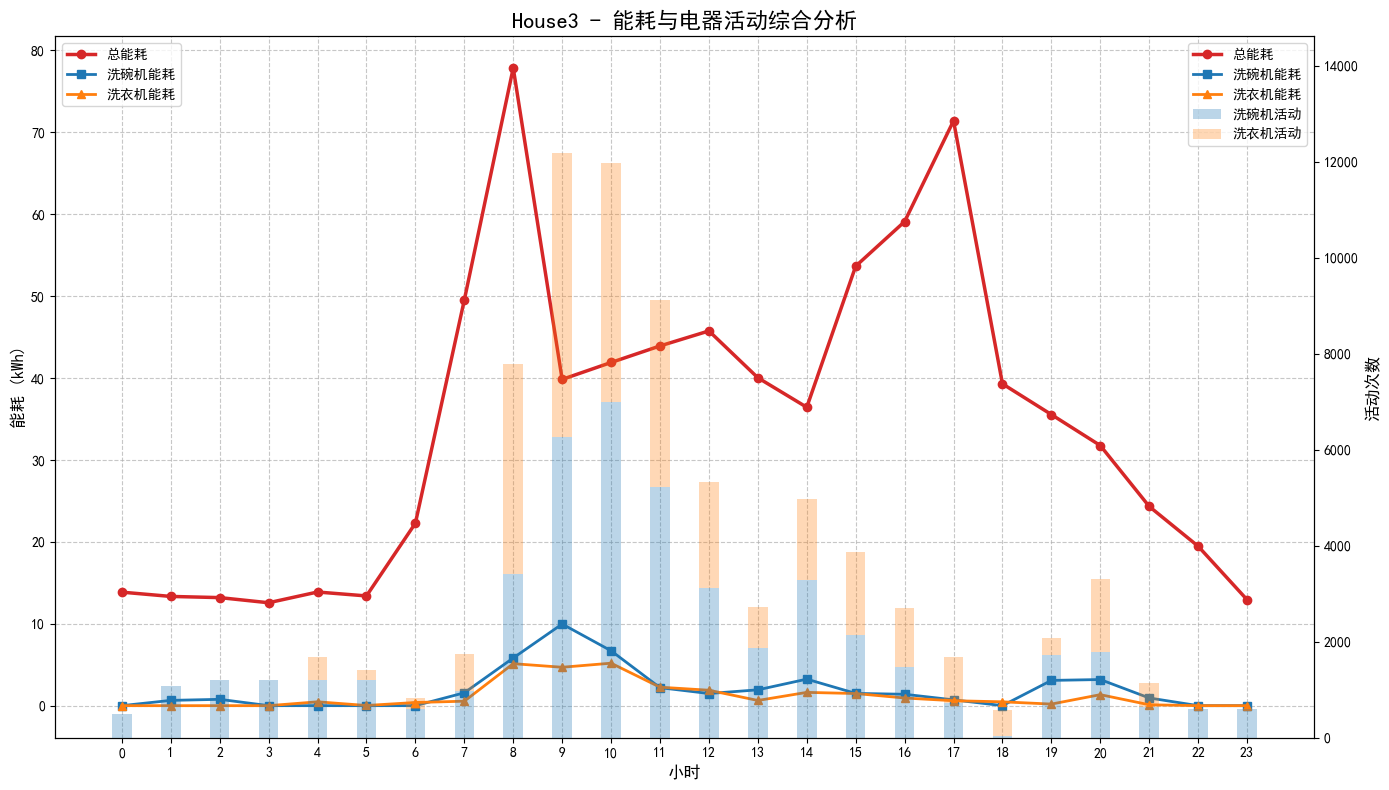


======= 分析 House4 小时能耗和电器活动 =======

House4 每小时能耗统计:
    Hour  Total_Energy  Dishwasher_Energy  WashingMachine_Energy  TimeDelta  \
0      0     19.421249           5.361559               0.104729  61.005000   
1      1     23.331387           9.161202               0.112117  59.989167   
2      2     25.488418          12.898964               0.101203  60.006111   
3      3     21.453668           7.525518               0.101097  60.002222   
4      4     24.211018           2.805607               0.098982  60.001111   
5      5     43.144402           0.878632               0.411217  59.991944   
6      6     54.393823           0.630318               0.539615  60.006944   
7      7     50.163723           1.272171               2.057139  59.994167   
8      8     45.393283           3.836393               2.543423  59.978611   
9      9     45.329713           4.037581               1.997126  60.006389   
10    10     44.512951           3.065837               1.846608  59.078056  

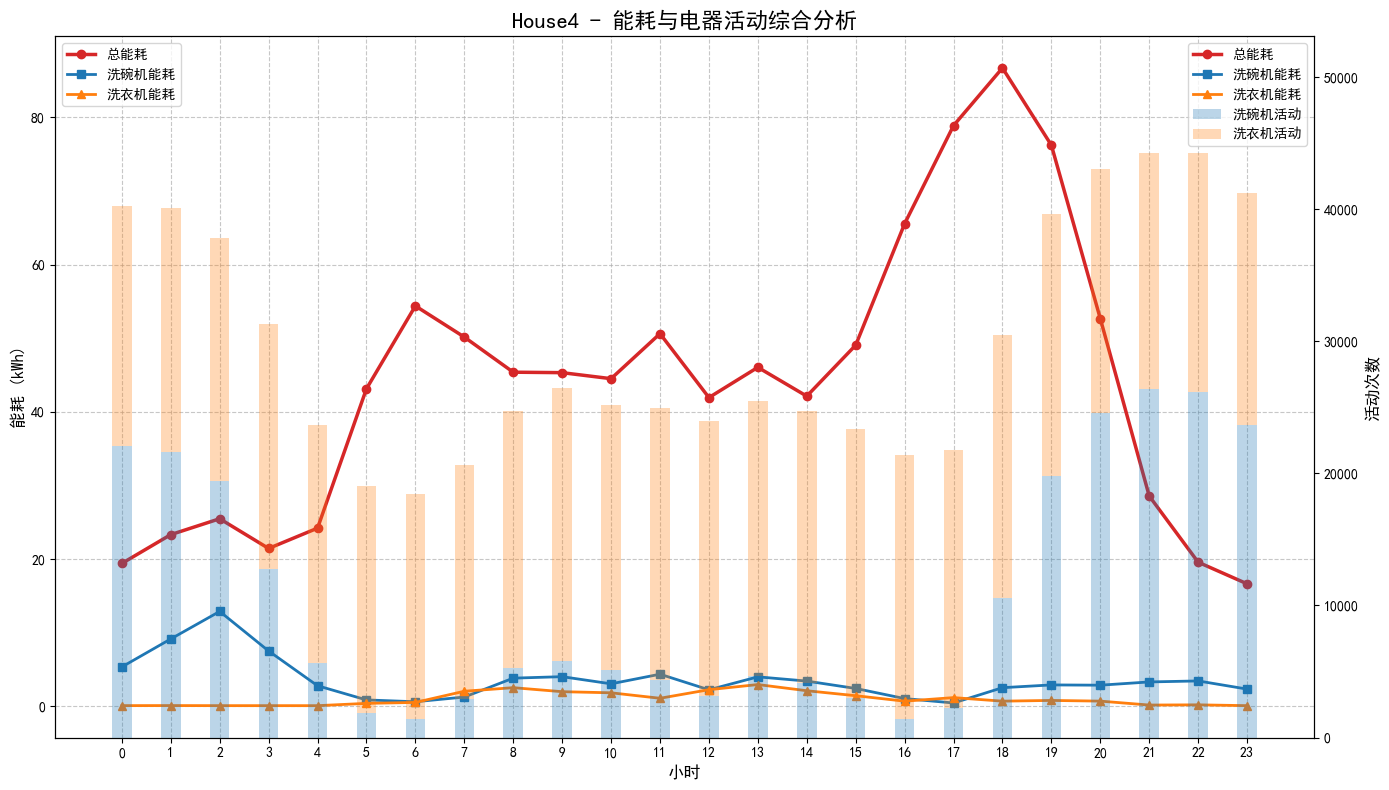


======= 分析 House5 小时能耗和电器活动 =======

House5 每小时能耗统计:
    Hour  Total_Energy  Dishwasher_Energy  WashingMachine_Energy  TimeDelta  \
0      0     25.168207           0.000000               0.000000  56.996111   
1      1     15.525911           0.000000               0.000000  56.941389   
2      2     13.798005           0.000000               0.000000  55.995000   
3      3     13.757748           0.000000               0.000000  56.001944   
4      4     13.929883           0.000000               0.000000  55.970556   
5      5     15.071109           0.000000               0.000000  55.983889   
6      6     15.335730           0.000000               0.000533  56.053889   
7      7     19.179719           0.000000               0.000000  55.986667   
8      8     24.766140           0.000000               0.000000  56.006389   
9      9     23.640295           0.000000               0.666817  55.999444   
10    10     27.175669           0.002491               2.256662  55.027222  

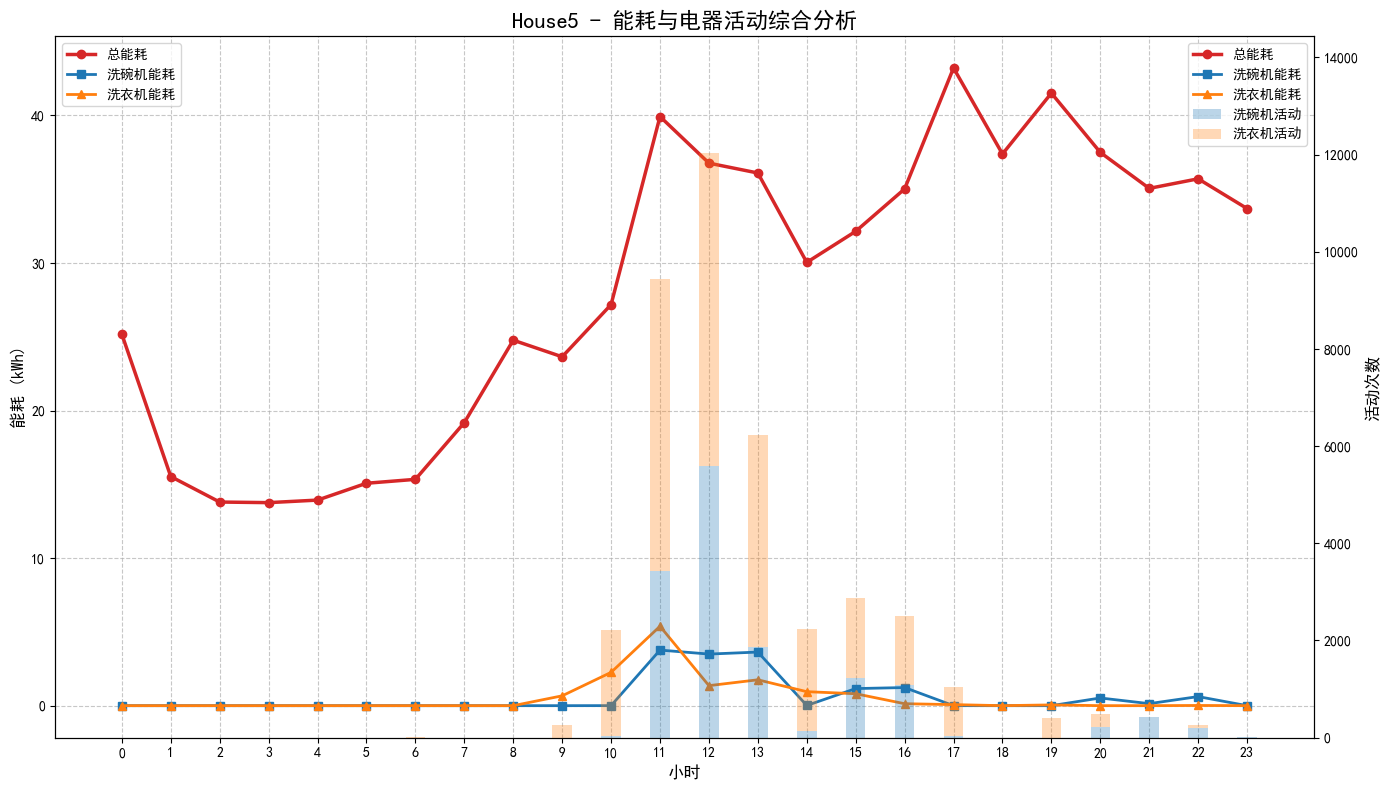


=== 所有家庭小时用电模式综合图表 ===


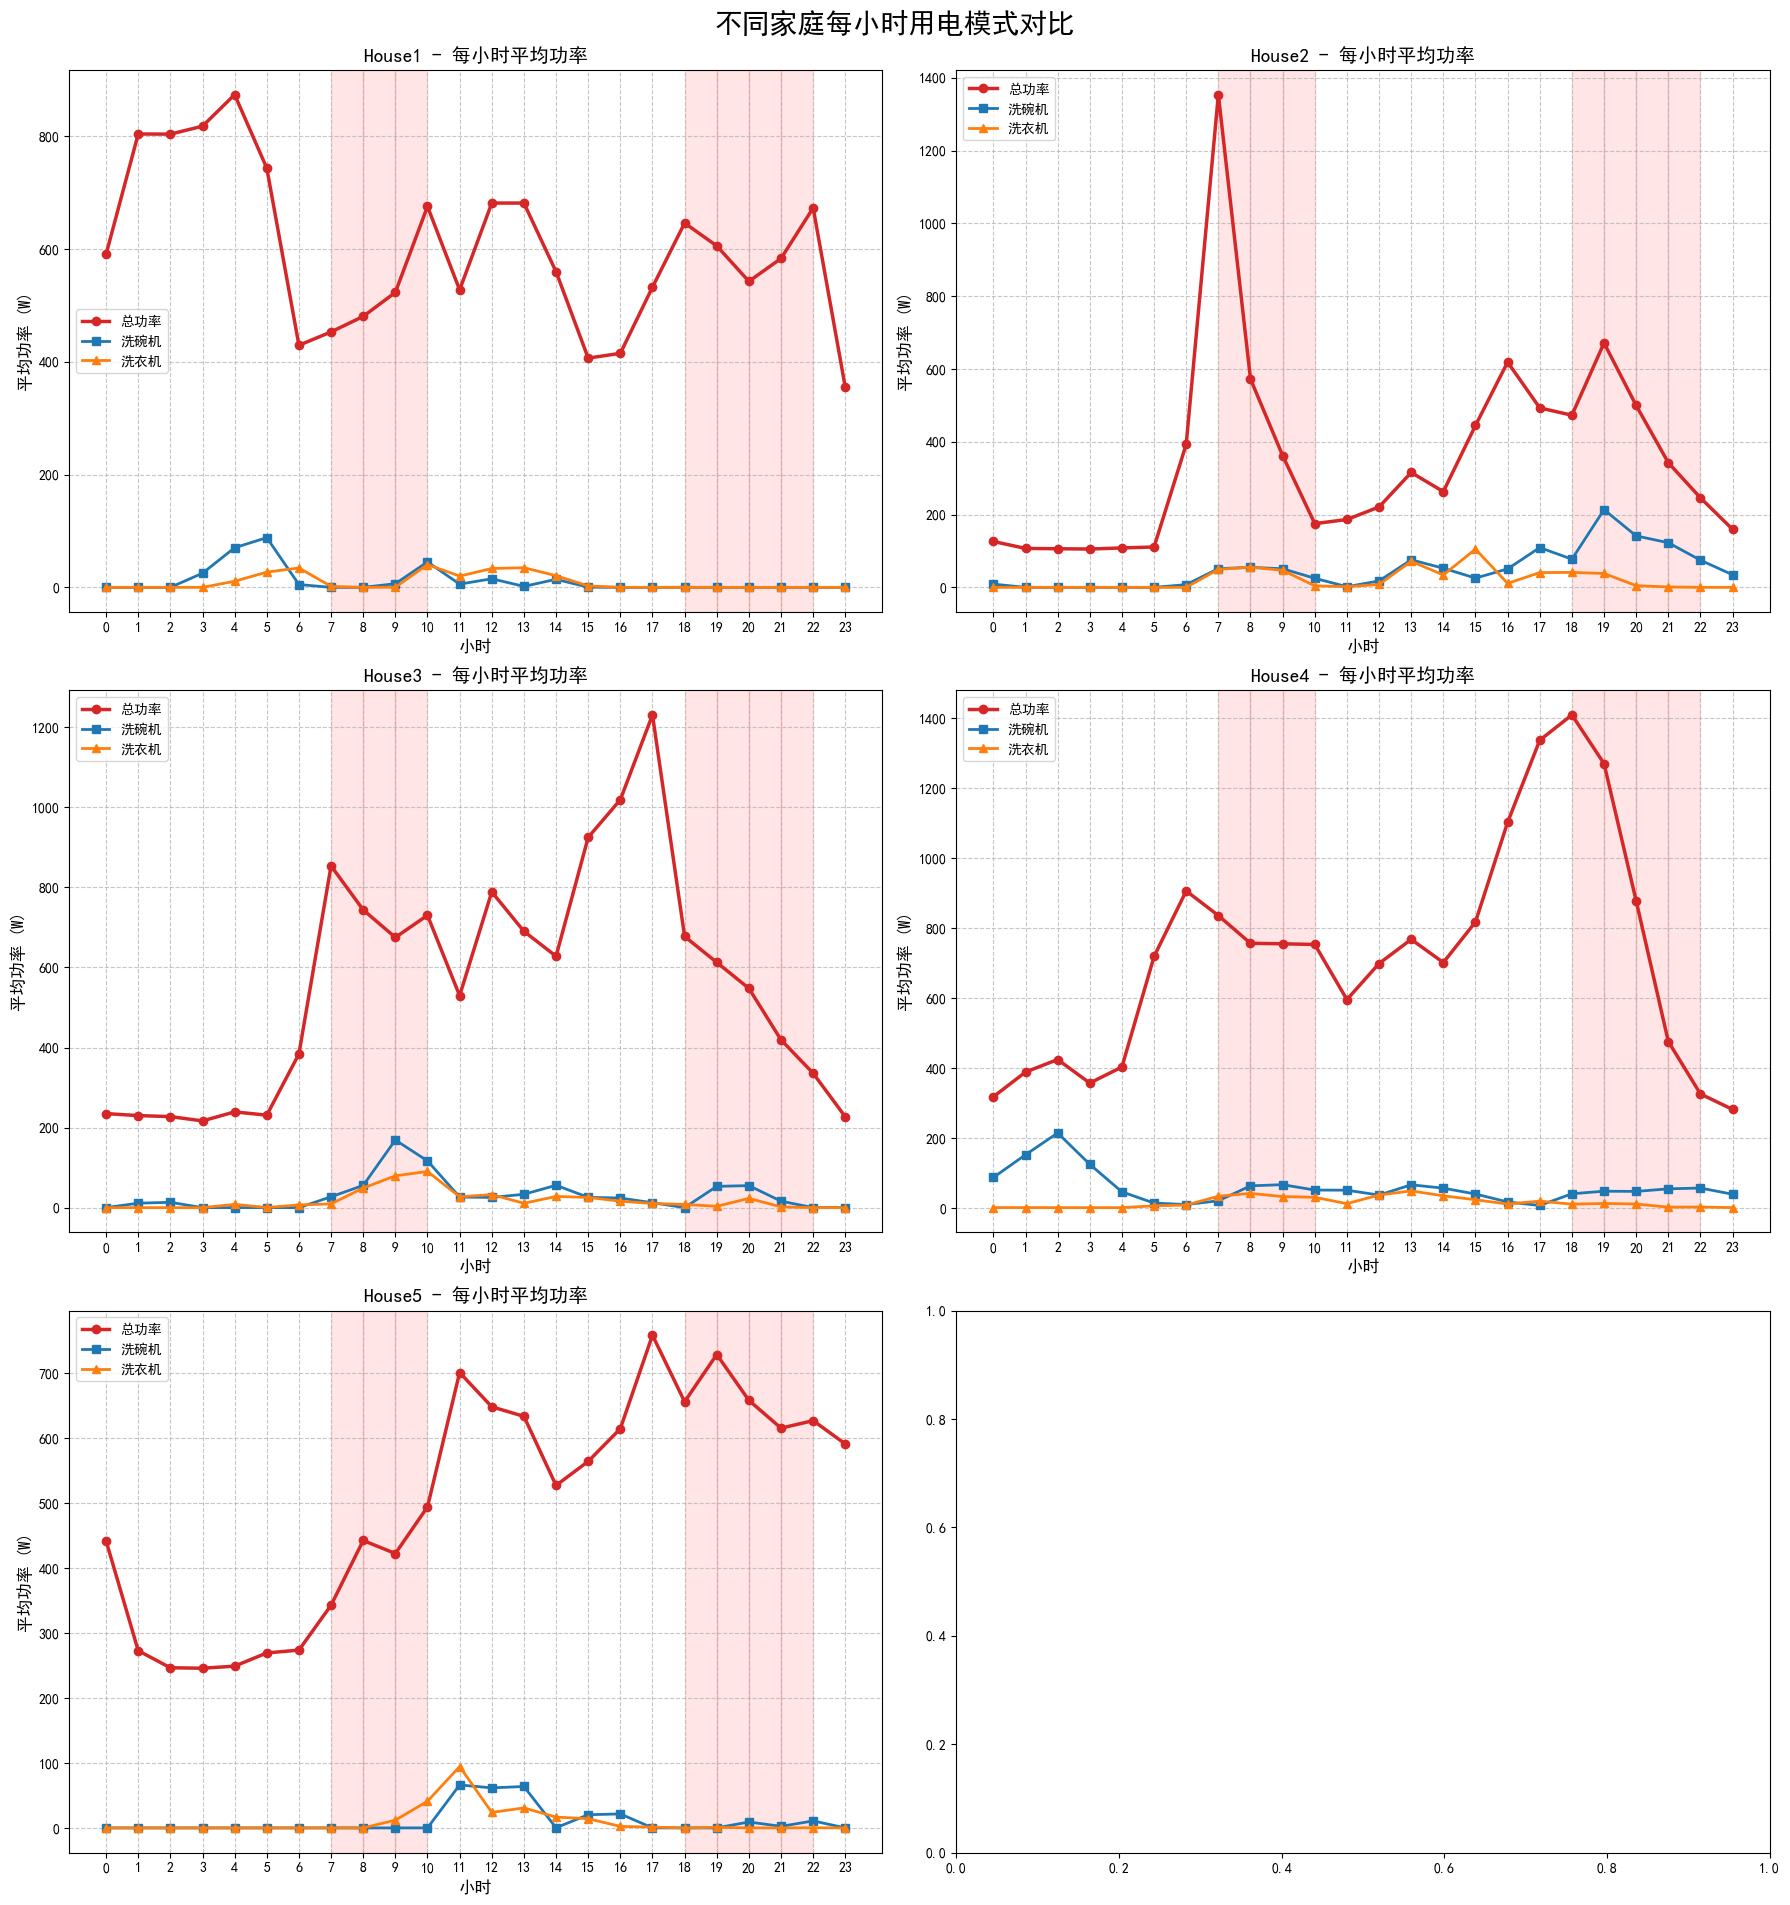

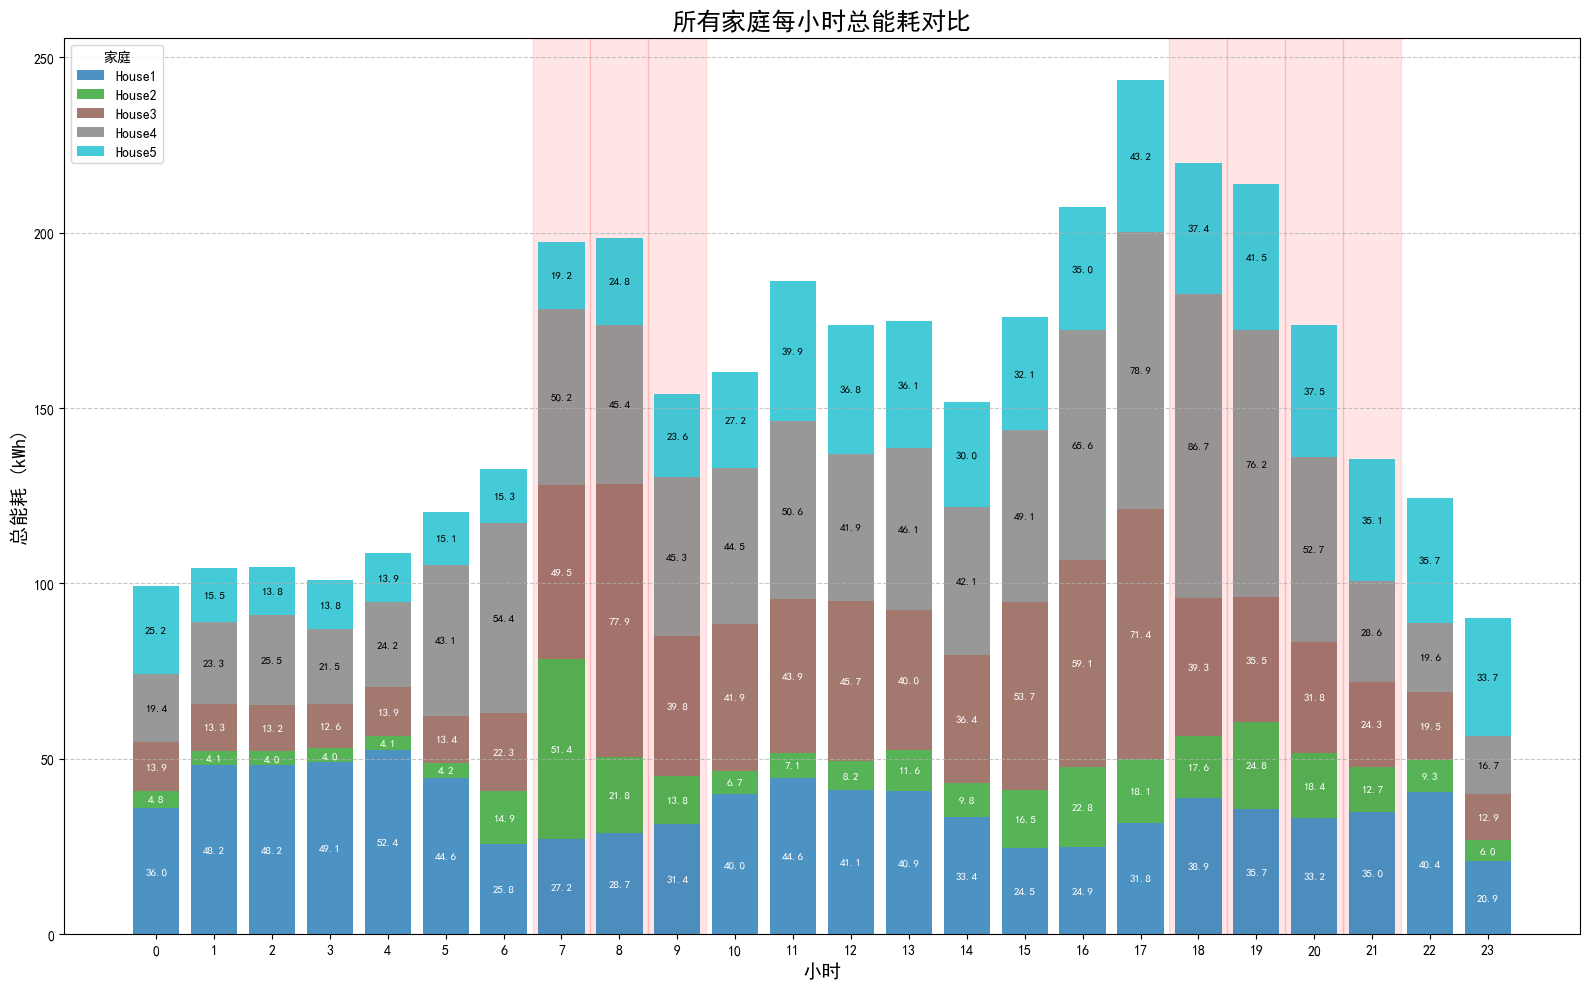

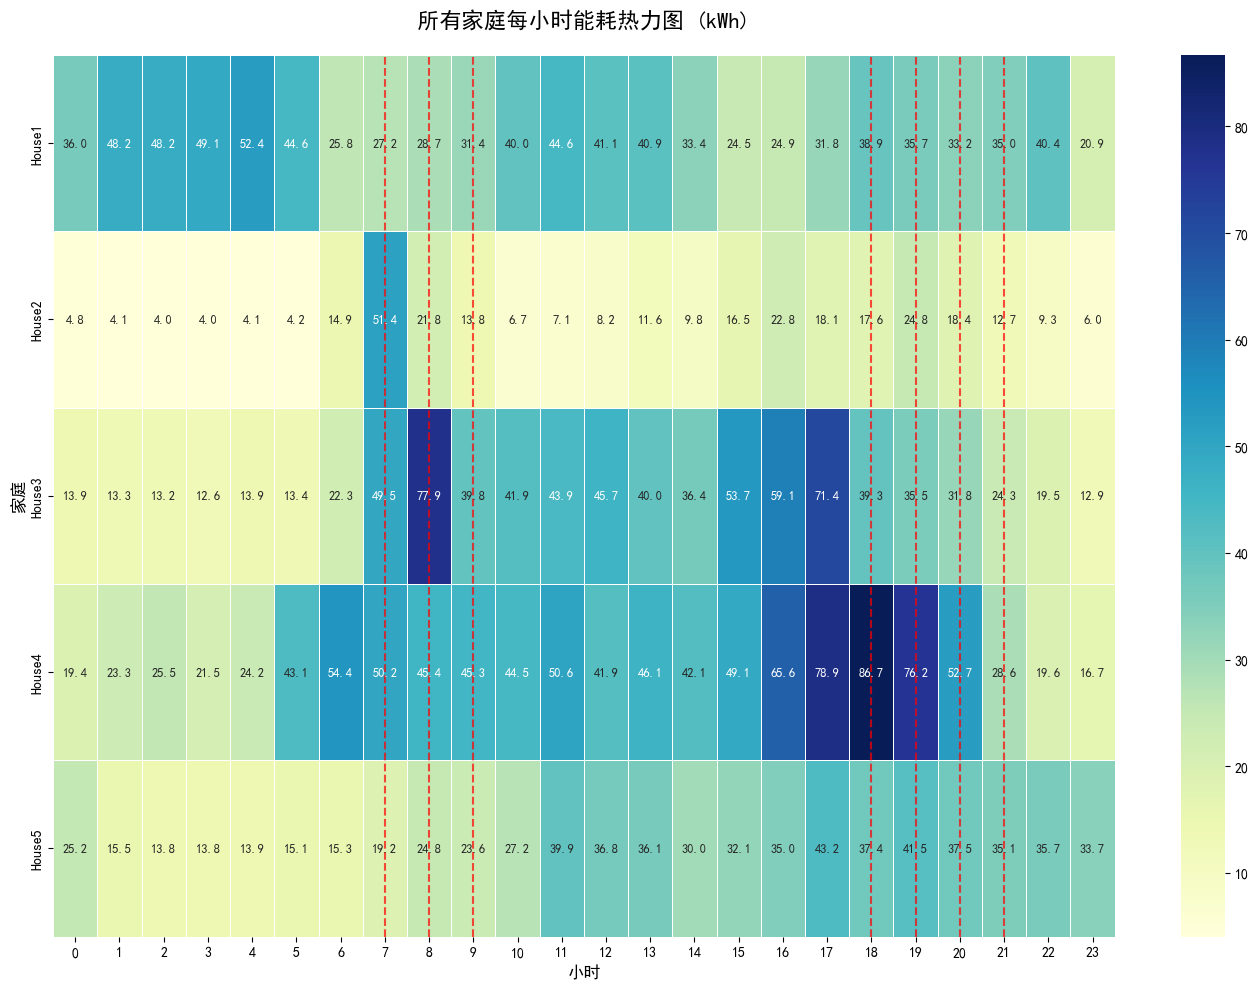

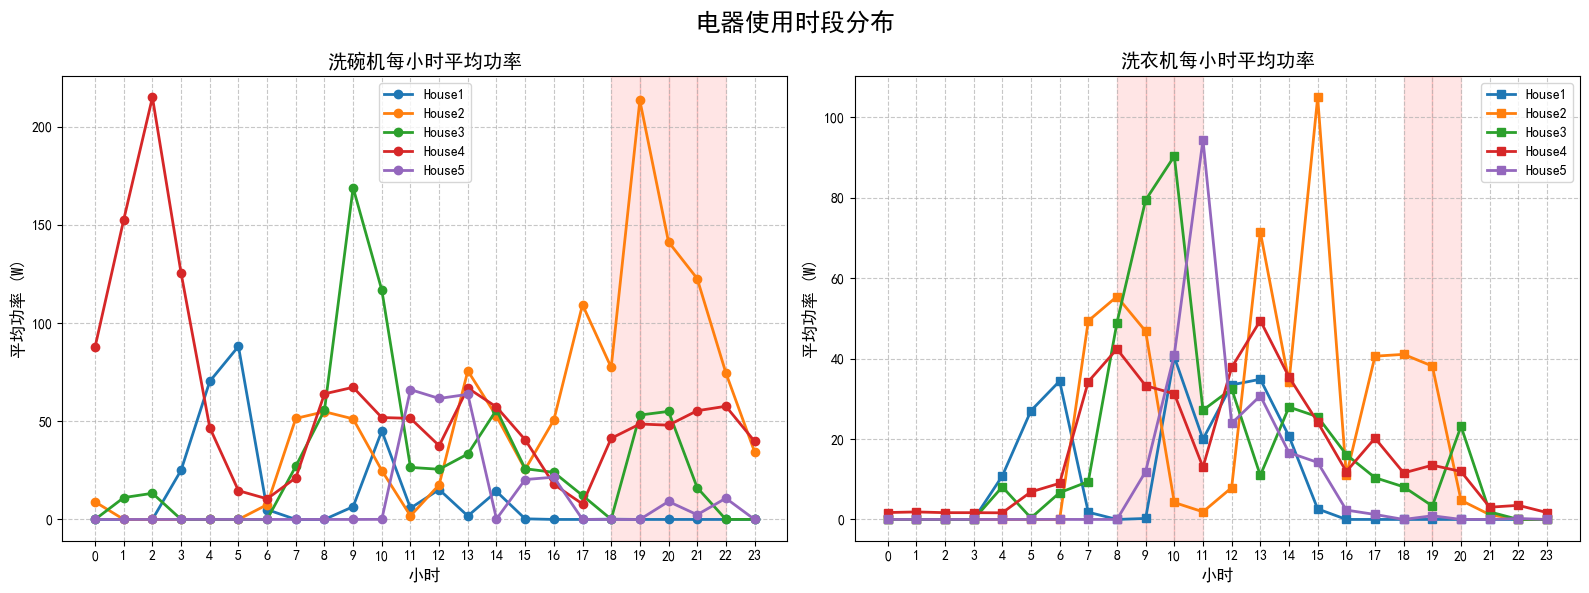

In [47]:
# ====================================================================
# 第一部分：小时分析（每小时能耗和电器活动）
# ====================================================================
print("\n======= 小时分析 =======")

# 初始化存储结果的字典
hourly_results = {}  # 存储(每小时能耗, 工作日能耗, 周末能耗)
appliance_activity_results = {}  # 存储电器活动数据

for i, (df_name, df) in enumerate(cleaned_dfs.items(), 1):
    house_name = f"House{i}"
    print(f"\n======= 分析 {house_name} 小时能耗和电器活动 =======")
    
    # 确保时间列是datetime类型
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    
    # 计算每小时能耗
    hourly_energy, weekday_energy, weekend_energy = calculate_hourly_energy(df, house_name)
    hourly_results[house_name] = (hourly_energy, weekday_energy, weekend_energy)
    
    # 分析电器活动
    activity = analyze_appliance_activity(df, house_name)
    appliance_activity_results[house_name] = activity
    
    # 生成综合图表（能耗+电器活动）
    plot_combined_analysis(hourly_energy, activity, house_name)

# 绘制所有家庭的小时用电模式
print("\n=== 所有家庭小时用电模式综合图表 ===")
plot_hourly_usage(hourly_results)
plot_hourly_energy_stacked(hourly_results)
plot_hourly_heatmap(hourly_results)
plot_appliance_usage_timing(hourly_results)


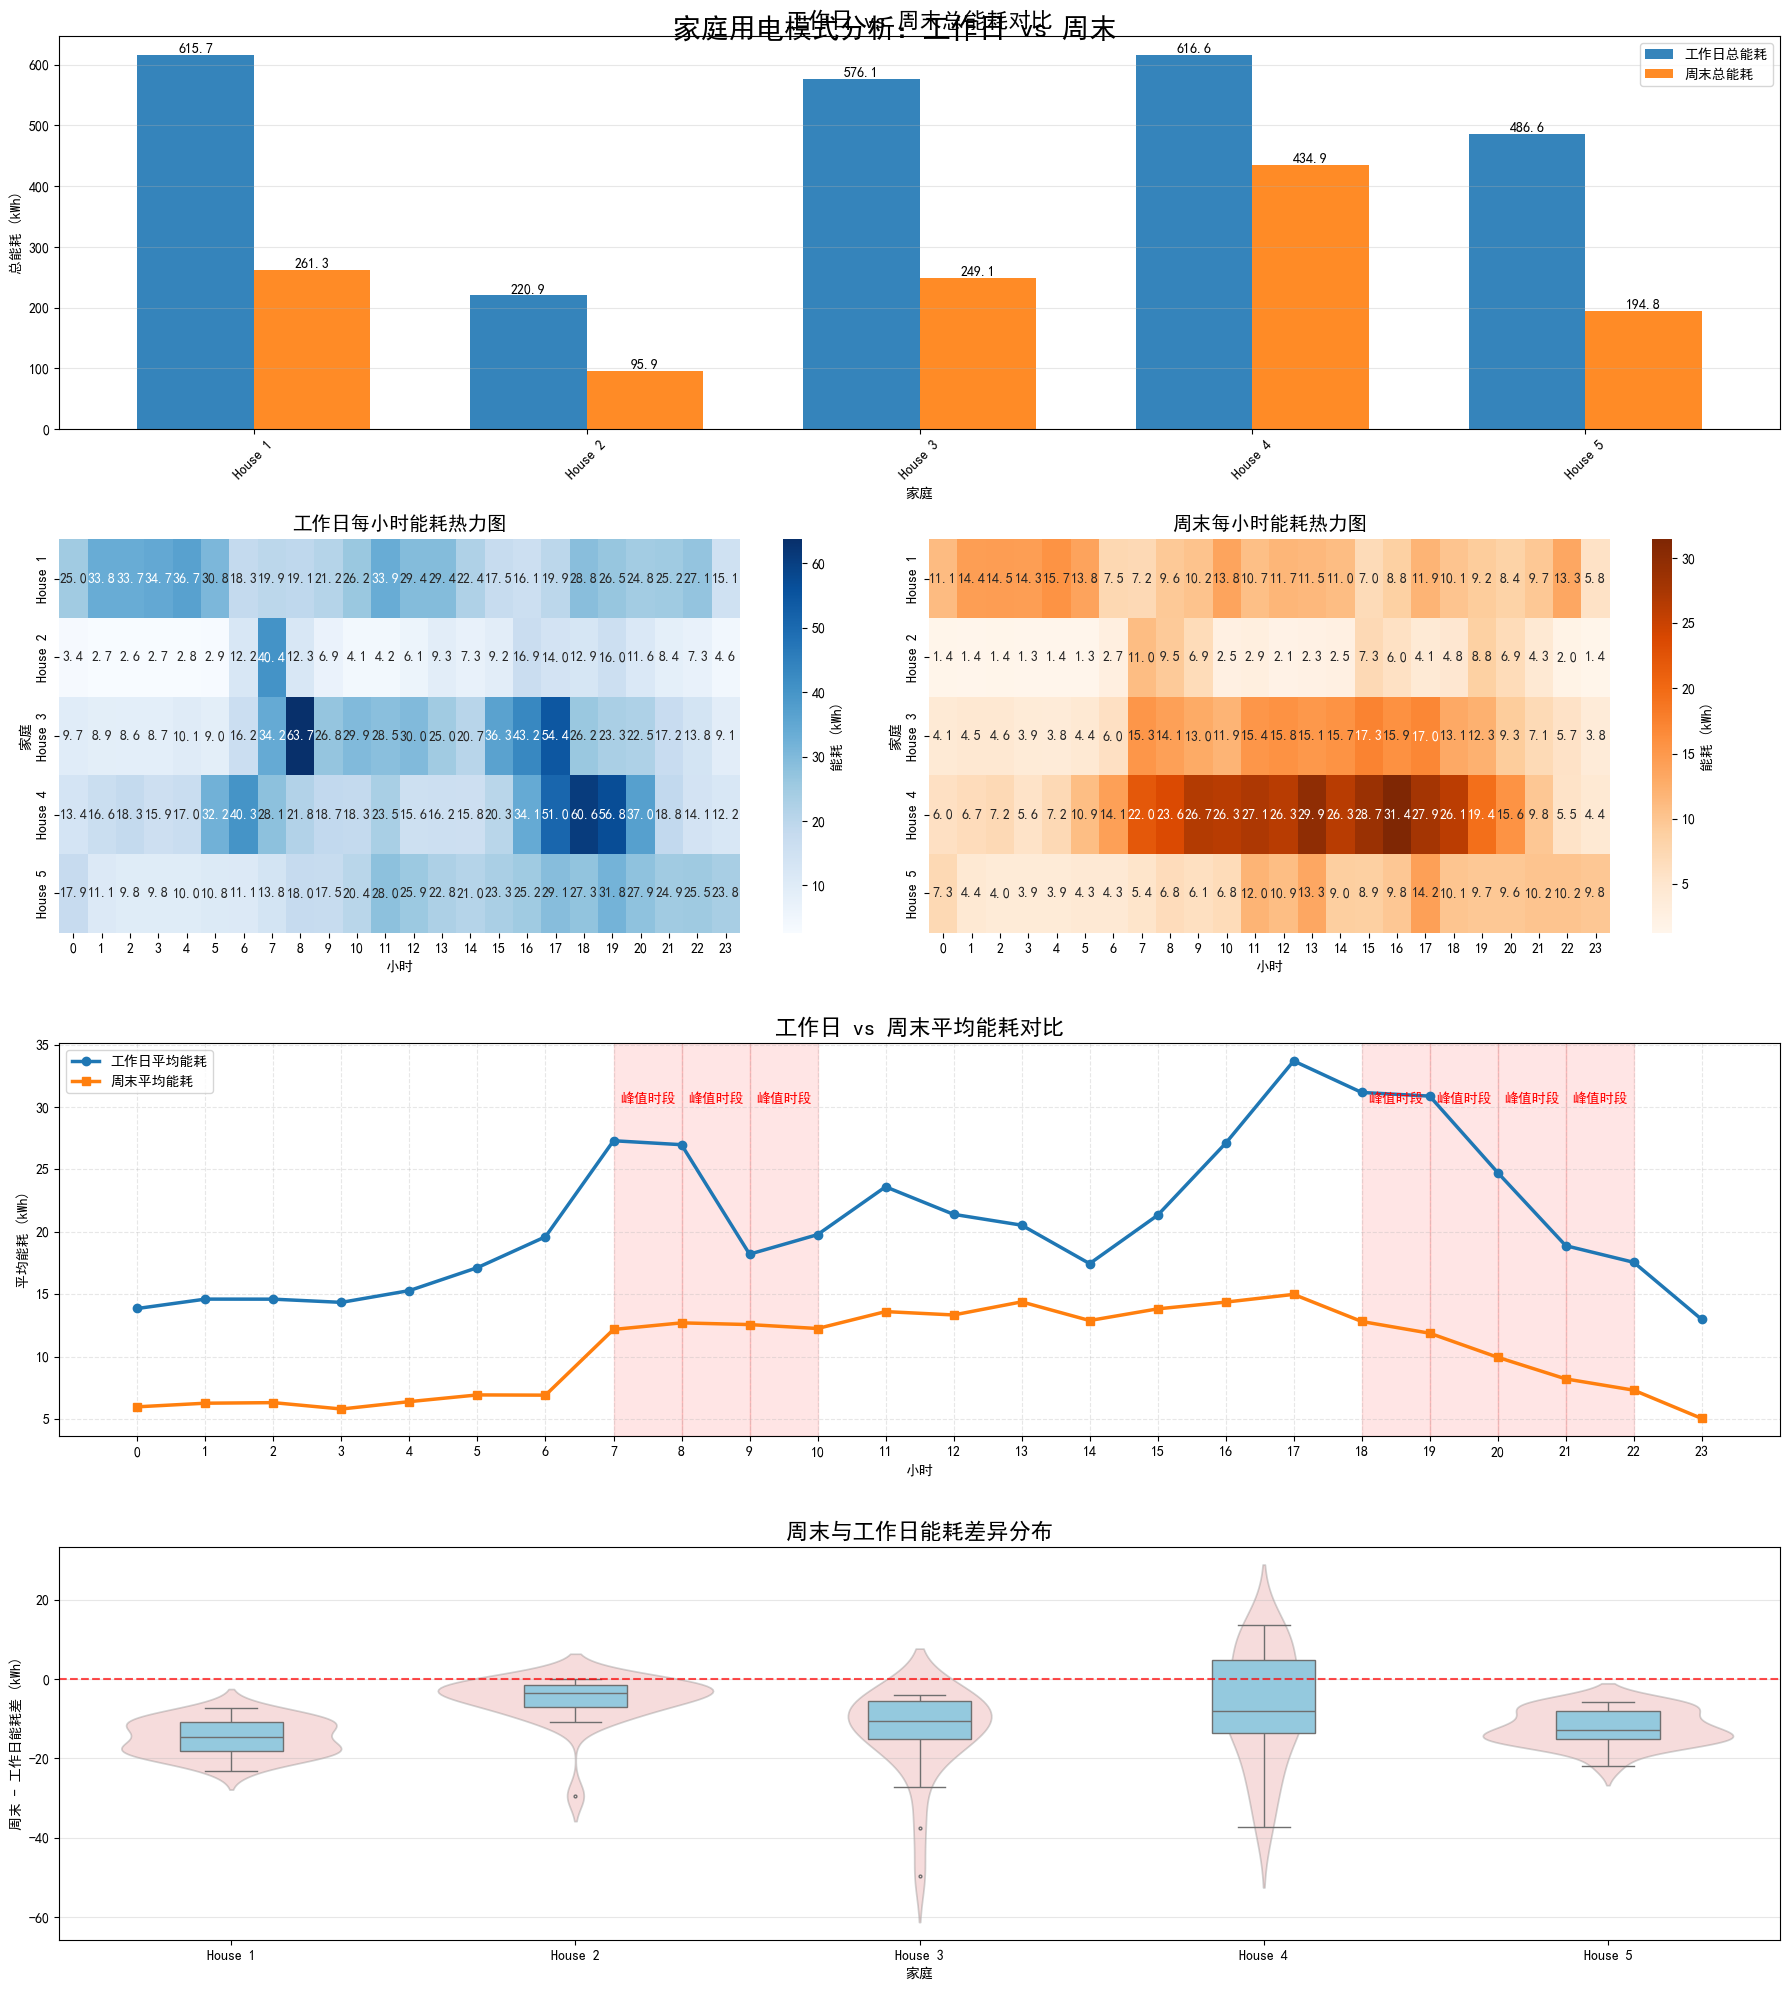

In [49]:
"""import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 数据加载
house1_df = pd.read_csv("house1.csv")
house2_df = pd.read_csv("house2.csv")
house3_df = pd.read_csv("house3.csv")
house4_df = pd.read_csv("house5.csv") 
house5_df = pd.read_csv("house6.csv")

# 统一列名（如果需要）
for df in [house1_df, house2_df, house3_df, house4_df, house5_df]:
    df.rename(columns={
        'timestamp': 'Time',
        'aggregate': 'Aggregate',
        'dish washer': 'dishwasher',
        'washing machine': 'washingmachine'
    }, inplace=True, errors='ignore')
"""
# 2. 能耗计算函数（改进版）
def calculate_hourly_energy(df, house_name):
    """计算每小时能耗（考虑实际时间间隔）并区分工作日/周末"""
    df = df.copy()
    
    # 确保时间列是datetime类型
    if 'Time' not in df.columns:
        raise ValueError(f"{house_name}数据中缺少'Time'列")
    
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    
    df = df.sort_values('Time')
    
    # 计算时间间隔（单位：小时）
    df['TimeDelta'] = df['Time'].diff().dt.total_seconds() / 3600
    if len(df) > 1:
        df.loc[df.index[0], 'TimeDelta'] = df.loc[df.index[1], 'TimeDelta']
    else:
        df.loc[df.index[0], 'TimeDelta'] = 1/60  # 默认1分钟
    
    # 计算能耗（kWh）
    df['Total_Energy'] = df['Aggregate'] * df['TimeDelta'] / 1000
    
    # 尝试计算各电器能耗（如果存在）
    if 'dishwasher' in df.columns:
        df['Dishwasher_Energy'] = df['dishwasher'] * df['TimeDelta'] / 1000
    else:
        df['Dishwasher_Energy'] = 0
        
    if 'washingmachine' in df.columns:
        df['WashingMachine_Energy'] = df['washingmachine'] * df['TimeDelta'] / 1000
    else:
        df['WashingMachine_Energy'] = 0
    
    # 提取时间信息
    df['Hour'] = df['Time'].dt.hour
    df['DayOfWeek'] = df['Time'].dt.dayofweek  # Monday=0, Sunday=6
    df['IsWeekend'] = df['DayOfWeek'] >= 5  # 周末标记
    
    # 按小时和工作日/周末分组统计
    hourly_energy = df.groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum',
        'TimeDelta': 'sum'  # 总时间长度
    }).reset_index()
    
    # 计算其他设备能耗
    hourly_energy['Other_Energy'] = (
        hourly_energy['Total_Energy'] - 
        hourly_energy['Dishwasher_Energy'] - 
        hourly_energy['WashingMachine_Energy']
    )
    
    # 按工作日/周末分组统计
    weekday_energy = df[~df['IsWeekend']].groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum'
    }).reset_index()
    
    weekend_energy = df[df['IsWeekend']].groupby('Hour').agg({
        'Total_Energy': 'sum',
        'Dishwasher_Energy': 'sum',
        'WashingMachine_Energy': 'sum'
    }).reset_index()
    
    return hourly_energy, weekday_energy, weekend_energy

# 3. 收集所有房屋数据
hourly_results = {}

# 对每个房屋进行处理
house1_hourly, house1_weekday, house1_weekend = calculate_hourly_energy(house1_df, "House 1")
hourly_results["House 1"] = (house1_hourly, house1_weekday, house1_weekend)

house2_hourly, house2_weekday, house2_weekend = calculate_hourly_energy(house2_df, "House 2")
hourly_results["House 2"] = (house2_hourly, house2_weekday, house2_weekend)

house3_hourly, house3_weekday, house3_weekend = calculate_hourly_energy(house3_df, "House 3")
hourly_results["House 3"] = (house3_hourly, house3_weekday, house3_weekend)

house4_hourly, house4_weekday, house4_weekend = calculate_hourly_energy(house4_df, "House 4")
hourly_results["House 4"] = (house4_hourly, house4_weekday, house4_weekend)

house5_hourly, house5_weekday, house5_weekend = calculate_hourly_energy(house5_df, "House 5")
hourly_results["House 5"] = (house5_hourly, house5_weekday, house5_weekend)

# 4. 工作日/非工作日分析函数
def analyze_weekday_weekend_patterns(hourly_results):
    """综合分析所有家庭工作日/非工作日用电模式"""
    # 准备数据结构
    weekday_totals = {}
    weekend_totals = {}
    weekday_hourly = {}
    weekend_hourly = {}
    
    # 收集数据
    for house_name, (_, weekday, weekend) in hourly_results.items():
        weekday_totals[house_name] = weekday['Total_Energy'].sum()
        weekend_totals[house_name] = weekend['Total_Energy'].sum()
        
        # 按小时收集数据
        weekday_hourly[house_name] = weekday.set_index('Hour')['Total_Energy']
        weekend_hourly[house_name] = weekend.set_index('Hour')['Total_Energy']
    
    # 转换为DataFrame
    weekday_hourly_df = pd.DataFrame(weekday_hourly)
    weekend_hourly_df = pd.DataFrame(weekend_hourly)
    
    # 填充缺失的小时（0-23）
    for hour in range(24):
        if hour not in weekday_hourly_df.index:
            weekday_hourly_df.loc[hour] = 0
        if hour not in weekend_hourly_df.index:
            weekend_hourly_df.loc[hour] = 0
    
    weekday_hourly_df = weekday_hourly_df.sort_index()
    weekend_hourly_df = weekend_hourly_df.sort_index()
    
    return {
        'weekday_totals': weekday_totals,
        'weekend_totals': weekend_totals,
        'weekday_hourly': weekday_hourly_df,
        'weekend_hourly': weekend_hourly_df
    }

# 5. 可视化函数
def visualize_weekday_weekend_patterns(analysis_results):
    """可视化工作日/非工作日用电模式"""
    weekday_totals = analysis_results['weekday_totals']
    weekend_totals = analysis_results['weekend_totals']
    weekday_hourly = analysis_results['weekday_hourly']
    weekend_hourly = analysis_results['weekend_hourly']
    
    houses = list(weekday_totals.keys())
    
    # 创建大图
    plt.figure(figsize=(18, 20))
    gs = GridSpec(4, 2, height_ratios=[1, 1, 1, 1])
    
    # 1. 总能耗对比（分组柱状图）
    ax1 = plt.subplot(gs[0, :])
    x = np.arange(len(houses))
    width = 0.35
    
    ax1.bar(x - width/2, [weekday_totals[h] for h in houses], width, 
            label='工作日总能耗', color='#1f77b4', alpha=0.9)
    ax1.bar(x + width/2, [weekend_totals[h] for h in houses], width, 
            label='周末总能耗', color='#ff7f0e', alpha=0.9)
    
    # 添加数值标签
    for i, val in enumerate([weekday_totals[h] for h in houses]):
        ax1.text(i - width/2, val + 0.1, f'{val:.1f}', ha='center', va='bottom')
    for i, val in enumerate([weekend_totals[h] for h in houses]):
        ax1.text(i + width/2, val + 0.1, f'{val:.1f}', ha='center', va='bottom')
    
    ax1.set_title('工作日 vs 周末总能耗对比', fontsize=16)
    ax1.set_xlabel('家庭')
    ax1.set_ylabel('总能耗 (kWh)')
    ax1.set_xticks(x)
    ax1.set_xticklabels(houses, rotation=45)
    ax1.legend()
    ax1.grid(axis='y', alpha=0.3)
    
    # 2. 小时能耗热力图（工作日+周末）
    ax2 = plt.subplot(gs[1, 0])
    sns.heatmap(
        weekday_hourly.T, 
        annot=True, 
        fmt=".1f", 
        cmap="Blues", 
        cbar_kws={'label': '能耗 (kWh)'},
        ax=ax2
    )
    ax2.set_title('工作日每小时能耗热力图', fontsize=14)
    ax2.set_xlabel('小时')
    ax2.set_ylabel('家庭')
    
    ax3 = plt.subplot(gs[1, 1])
    sns.heatmap(
        weekend_hourly.T, 
        annot=True, 
        fmt=".1f", 
        cmap="Oranges", 
        cbar_kws={'label': '能耗 (kWh)'},
        ax=ax3
    )
    ax3.set_title('周末每小时能耗热力图', fontsize=14)
    ax3.set_xlabel('小时')
    ax3.set_ylabel('家庭')
    
    # 3. 平均能耗对比曲线
    ax4 = plt.subplot(gs[2, :])
    # 计算工作日和周末的平均能耗曲线
    weekday_avg = weekday_hourly.mean(axis=1)
    weekend_avg = weekend_hourly.mean(axis=1)
    
    ax4.plot(weekday_avg.index, weekday_avg, 
             label='工作日平均能耗', color='#1f77b4', linewidth=2.5, marker='o')
    ax4.plot(weekend_avg.index, weekend_avg, 
             label='周末平均能耗', color='#ff7f0e', linewidth=2.5, marker='s')
    
    # 添加峰值时段标记
    peak_hours = [7, 8, 9, 18, 19, 20, 21]
    for hour in peak_hours:
        ax4.axvspan(hour, hour+1, alpha=0.1, color='red')
        ax4.text(hour+0.5, max(weekday_avg.max(), weekend_avg.max())*0.9, 
                '峰值时段', ha='center', fontsize=10, color='red')
    
    ax4.set_title('工作日 vs 周末平均能耗对比', fontsize=16)
    ax4.set_xlabel('小时')
    ax4.set_ylabel('平均能耗 (kWh)')
    ax4.set_xticks(range(0, 24))
    ax4.grid(True, linestyle='--', alpha=0.3)
    ax4.legend()
    
    # 4. 能耗差异分析
    ax5 = plt.subplot(gs[3, :])
    # 计算每个家庭周末与工作日的能耗差异
    diff_data = []
    for house in houses:
        for hour in range(24):
            weekday_val = weekday_hourly.loc[hour, house] if hour in weekday_hourly.index else 0
            weekend_val = weekend_hourly.loc[hour, house] if hour in weekend_hourly.index else 0
            diff = weekend_val - weekday_val
            diff_data.append({'House': house, 'Hour': hour, 'Difference': diff})
    
    diff_df = pd.DataFrame(diff_data)
    
    # 绘制箱线图和小提琴图组合
    sns.boxplot(x='House', y='Difference', data=diff_df, ax=ax5, 
                width=0.3, color='skyblue', fliersize=2)
    sns.violinplot(x='House', y='Difference', data=diff_df, ax=ax5,
                   inner=None, color='lightcoral', alpha=0.3)
    
    ax5.axhline(0, color='r', linestyle='--', alpha=0.7)
    ax5.set_title('周末与工作日能耗差异分布', fontsize=16)
    ax5.set_xlabel('家庭')
    ax5.set_ylabel('周末 - 工作日能耗差 (kWh)')
    ax5.grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle('家庭用电模式分析：工作日 vs 周末', fontsize=20, y=0.99)
    plt.show()

# 6. 执行分析并可视化
analysis_results = analyze_weekday_weekend_patterns(hourly_results)
visualize_weekday_weekend_patterns(analysis_results)


=== 季度能耗环状图 ===


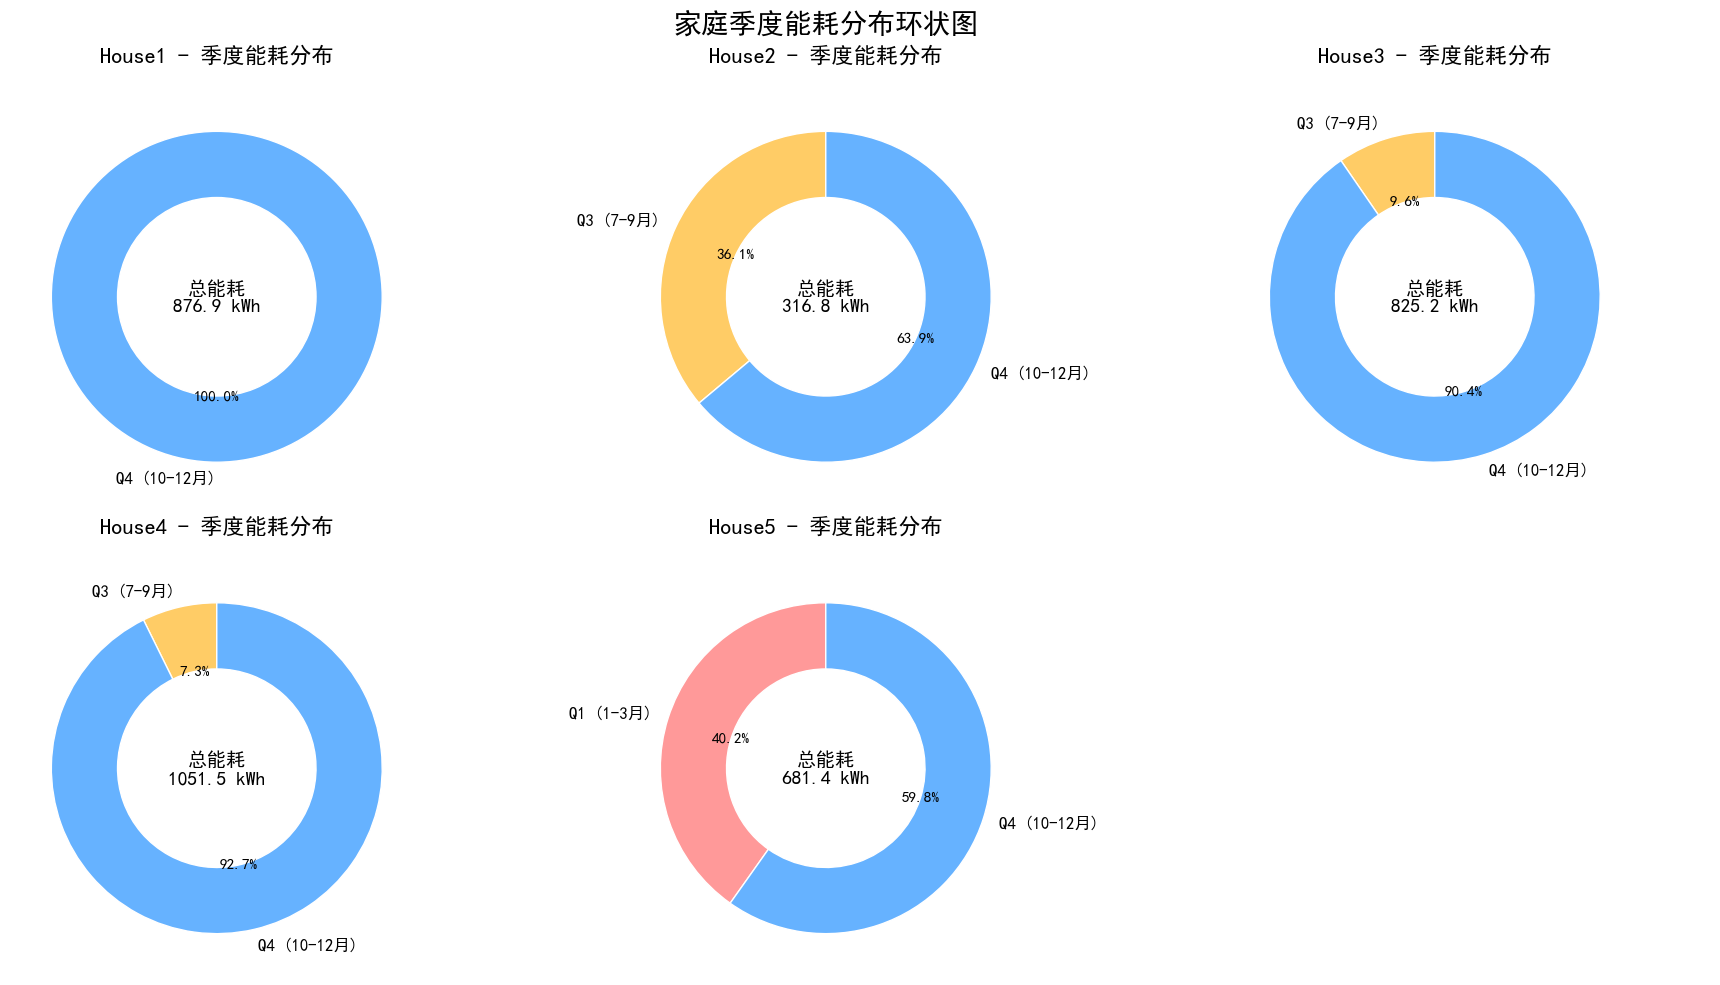


=== 按季度堆叠的家庭能耗图 ===


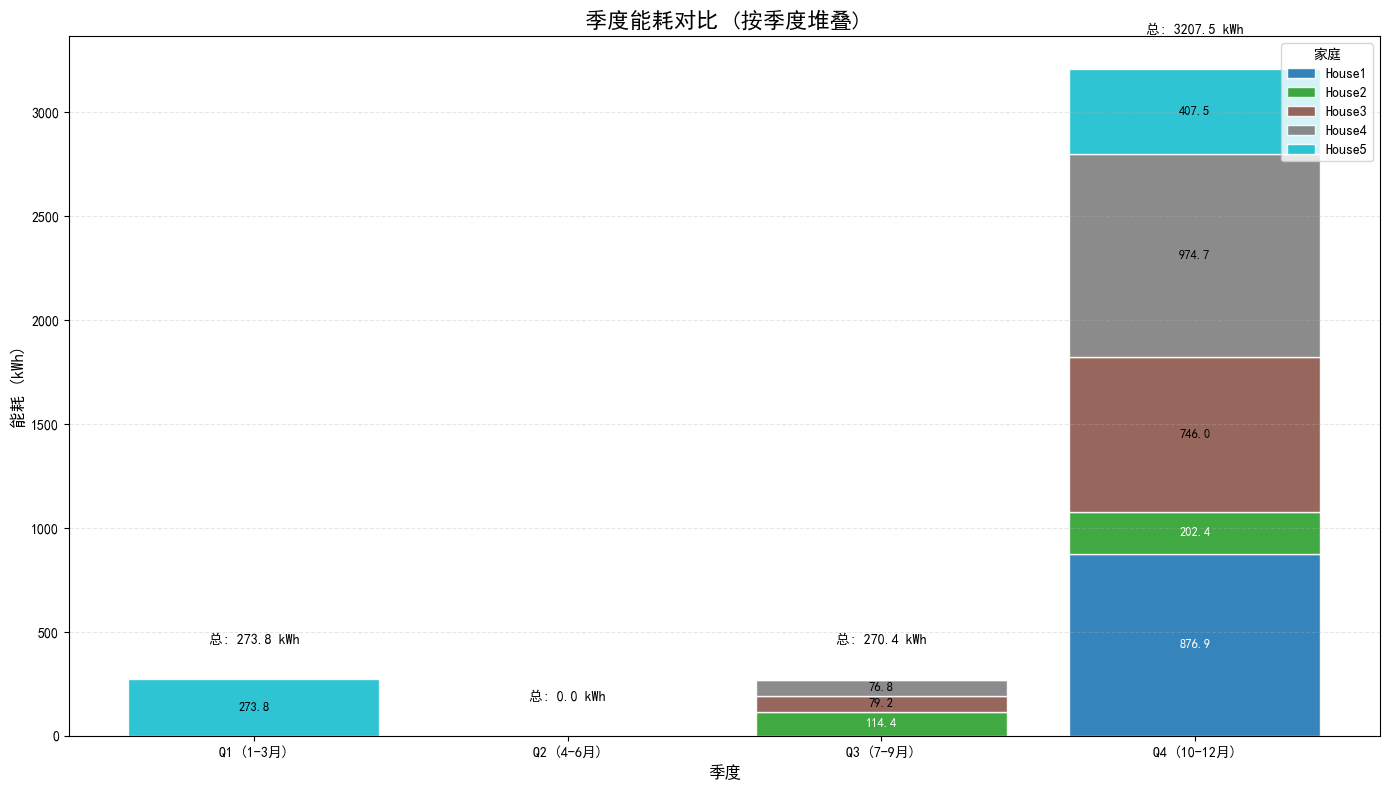


=== 季度能耗热力图 ===


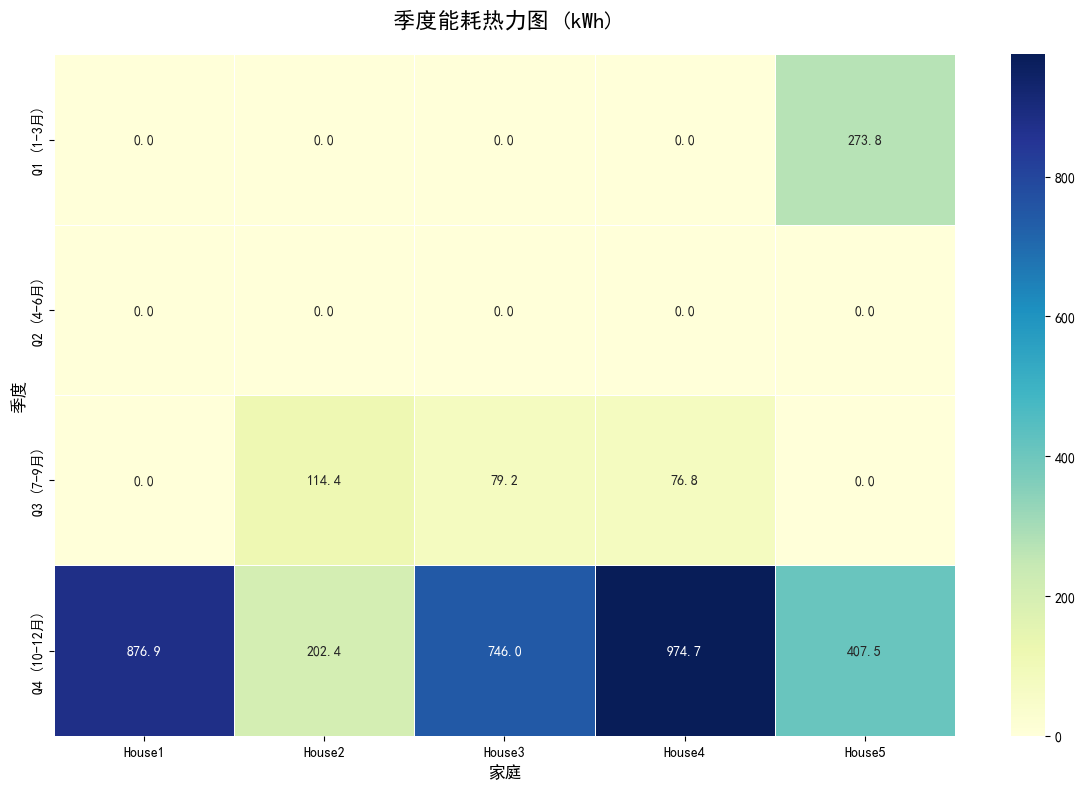


======= 季度总结 =======

House1 季度能耗总结:
年度总能耗: 876.94 kWh
Q4 (10-12月): 876.94 kWh (100.0%)
能耗最高的季度: Q4 (10-12月) (876.94 kWh)
洗碗机能耗占比: 1.91%
洗衣机能耗占比: 1.60%
其他设备能耗占比: 96.49%

House2 季度能耗总结:
年度总能耗: 316.82 kWh
Q3 (7-9月): 114.40 kWh (36.1%)
Q4 (10-12月): 202.42 kWh (63.9%)
能耗最高的季度: Q4 (10-12月) (202.42 kWh)
洗碗机能耗占比: 14.06%
洗衣机能耗占比: 6.04%
其他设备能耗占比: 79.91%

House3 季度能耗总结:
年度总能耗: 825.18 kWh
Q3 (7-9月): 79.23 kWh (9.6%)
Q4 (10-12月): 745.95 kWh (90.4%)
能耗最高的季度: Q4 (10-12月) (745.95 kWh)
洗碗机能耗占比: 5.47%
洗衣机能耗占比: 3.39%
其他设备能耗占比: 91.14%

House4 季度能耗总结:
年度总能耗: 1051.54 kWh
Q3 (7-9月): 76.81 kWh (7.3%)
Q4 (10-12月): 974.74 kWh (92.7%)
能耗最高的季度: Q4 (10-12月) (974.74 kWh)
洗碗机能耗占比: 8.27%
洗衣机能耗占比: 2.33%
其他设备能耗占比: 89.40%

House5 季度能耗总结:
年度总能耗: 681.35 kWh
Q1 (1-3月): 273.85 kWh (40.2%)
Q4 (10-12月): 407.50 kWh (59.8%)
能耗最高的季度: Q4 (10-12月) (407.50 kWh)
洗碗机能耗占比: 2.14%
洗衣机能耗占比: 1.97%
其他设备能耗占比: 95.89%


In [51]:
# ====================================================================
# 第三部分：季度分析
# ====================================================================
# ======================= 季度能耗计算函数 =======================
def calculate_quarterly_energy(df, house_name):
    # 确保时间列是datetime类型
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    
    # 按时间排序
    df = df.sort_values('Time')
    
    # 计算时间间隔（小时）
    df['Time_Interval'] = df['Time'].diff().dt.total_seconds().fillna(0) / 3600
    
    # 计算每条记录的能耗 (kWh) = 功率(W) * 时间间隔(h) / 1000
    df['Total_Energy'] = df['Aggregate'] * df['Time_Interval'] / 1000
    df['Dishwasher_Energy'] = df['dishwasher'] * df['Time_Interval'] / 1000
    df['WashingMachine_Energy'] = df['washingmachine'] * df['Time_Interval'] / 1000
    
    # 添加季度列
    df['Quarter'] = df['Time'].dt.quarter
    
    # 季度名称映射
    quarter_names = {
        1: 'Q1 (1-3月)',
        2: 'Q2 (4-6月)',
        3: 'Q3 (7-9月)',
        4: 'Q4 (10-12月)'
    }
    
    # 按季度分组计算能耗
    quarterly_energy = df.groupby('Quarter').agg(
        Total_Energy=('Total_Energy', 'sum'),
        Dishwasher_Energy=('Dishwasher_Energy', 'sum'),
        WashingMachine_Energy=('WashingMachine_Energy', 'sum')
    ).reset_index()
    
    # 添加季度名称列
    quarterly_energy['Quarter_Name'] = quarterly_energy['Quarter'].map(quarter_names)
    quarterly_energy['House'] = house_name
    
    return quarterly_energy

# ======================= 季度分析函数 - 环状图版本 =======================
def plot_quarterly_donut(quarterly_results):
    """绘制每个家庭的季度能耗环状图"""
    # 设置颜色映射
    quarter_colors = {
        'Q1 (1-3月)': '#FF9999',
        'Q2 (4-6月)': '#66B266',
        'Q3 (7-9月)': '#FFCC66',
        'Q4 (10-12月)': '#66B2FF'
    }
    
    # 创建子图布局
    n_houses = len(quarterly_results)
    n_cols = min(3, n_houses)
    n_rows = (n_houses + n_cols - 1) // n_cols
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*6, n_rows*5))
    
    # 如果只有一个子图，确保axes是数组
    if n_houses == 1:
        axes = np.array([axes])
    axes = axes.flatten()
    
    for i, (house_name, q_data) in enumerate(quarterly_results.items()):
        ax = axes[i]
        
        # 确保数据按季度排序
        q_data = q_data.sort_values('Quarter')
        
        # 准备数据
        labels = q_data['Quarter_Name']
        sizes = q_data['Total_Energy']
        colors = [quarter_colors[q] for q in labels]
        
        # 创建环状图
        wedges, texts, autotexts = ax.pie(
            sizes, 
            labels=labels, 
            colors=colors,
            autopct='%1.1f%%',
            startangle=90,
            wedgeprops=dict(width=0.4, edgecolor='w'),
            textprops={'fontsize': 12}
        )
        
        # 设置标题
        ax.set_title(f'{house_name} - 季度能耗分布', fontsize=16, pad=20)
        
        # 添加中心文本
        total_energy = sizes.sum()
        ax.text(0, 0, f'总能耗\n{total_energy:.1f} kWh', 
                ha='center', va='center', fontsize=14, fontweight='bold')
        
        # 调整标签位置
        for text in texts:
            text.set_fontsize(12)
        for autotext in autotexts:
            autotext.set_fontsize(11)
            autotext.set_fontweight('bold')
    
    # 隐藏多余的子图
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.suptitle('家庭季度能耗分布环状图', fontsize=20)
    plt.show()

def plot_quarterly_stacked_by_quarter(quarterly_results):
    """按季度堆叠的家庭能耗图"""
    plt.figure(figsize=(14, 8))
    
    # 准备季度顺序
    quarters = ['Q1 (1-3月)', 'Q2 (4-6月)', 'Q3 (7-9月)', 'Q4 (10-12月)']
    house_names = list(quarterly_results.keys())
    
    # 设置颜色映射
    colors = plt.cm.tab10(np.linspace(0, 1, len(house_names)))
    
    # 创建矩阵存储每个季度各家庭能耗
    energy_data = {h: [] for h in house_names}
    
    # 填充数据
    for q in quarters:
        for house_name in house_names:
            q_data = quarterly_results[house_name]
            q_value = q_data[q_data['Quarter_Name'] == q]['Total_Energy']
            energy_data[house_name].append(q_value.values[0] if not q_value.empty else 0)
    
    # 创建堆叠柱状图
    bottom = np.zeros(len(quarters))
    
    for i, house_name in enumerate(house_names):
        values = energy_data[house_name]
        plt.bar(
            quarters, 
            values, 
            bottom=bottom,
            label=house_name,
            color=colors[i],
            edgecolor='white',
            alpha=0.9
        )
        
        # 添加数据标签
        for j, value in enumerate(values):
            if value > 0:  # 只显示大于0的标签
                plt.text(
                    j, 
                    bottom[j] + value/2, 
                    f'{value:.1f}',
                    ha='center', 
                    va='center',
                    fontsize=9,
                    color='white' if i < 2 else 'black'
                )
        
        # 更新底部位置
        bottom = np.add(bottom, values)
    
    # 设置图表属性
    plt.title('季度能耗对比 (按季度堆叠)', fontsize=16)
    plt.xlabel('季度', fontsize=12)
    plt.ylabel('能耗 (kWh)', fontsize=12)
    plt.legend(title='家庭', loc='upper right')
    plt.grid(True, linestyle='--', alpha=0.3, axis='y')
    
    # 添加总能耗标签
    total_energy = [sum(energy_data[h][i] for h in house_names) for i in range(len(quarters))]
    for j, total in enumerate(total_energy):
        plt.text(
            j, 
            total + max(total_energy)*0.05,  # 在柱子顶部上方5%位置显示
            f'总: {total:.1f} kWh',
            ha='center', 
            va='bottom',
            fontsize=10,
            fontweight='bold'
        )
    
    plt.tight_layout()
    plt.show()

def plot_quarterly_heatmap(quarterly_results):
    """绘制所有家庭每季度能耗热力图"""
    # 准备季度顺序
    quarter_order = ['Q1 (1-3月)', 'Q2 (4-6月)', 'Q3 (7-9月)', 'Q4 (10-12月)']
    
    # 创建数据矩阵
    heatmap_data = pd.DataFrame(index=quarter_order)
    
    # 填充数据
    for house_name, q_data in quarterly_results.items():
        # 确保数据按季度排序
        q_data = q_data.sort_values('Quarter')
        
        # 获取季度能耗值
        values = []
        for q in quarter_order:
            q_value = q_data[q_data['Quarter_Name'] == q]['Total_Energy']
            values.append(q_value.values[0] if not q_value.empty else 0)
        
        heatmap_data[house_name] = values
    
    # 创建热力图
    plt.figure(figsize=(12, 8))
    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        linewidths=0.5,
        annot_kws={"size": 10}
    )
    
    # 设置图表属性
    plt.title('季度能耗热力图 (kWh)', fontsize=16, pad=20)
    plt.xlabel('家庭', fontsize=12)
    plt.ylabel('季度', fontsize=12)
    
    plt.tight_layout()
    plt.show()

# ======================= 季度分析主流程 =======================
#print("\n======= 季度分析 =======")
quarterly_results = {}

for i, (df_name, df) in enumerate(cleaned_dfs.items(), 1):
    house_name = f"House{i}"
    #print(f"\n======= 分析 {house_name} 季度能耗 =======")
    
    # 确保时间列是datetime类型
    if not pd.api.types.is_datetime64_any_dtype(df['Time']):
        df['Time'] = pd.to_datetime(df['Time'])
    
    # 使用修复后的函数计算季度能耗
    quarterly_energy = calculate_quarterly_energy(df, house_name)
    quarterly_results[house_name] = quarterly_energy

# 季度可视化 - 环状图
print("\n=== 季度能耗环状图 ===")
plot_quarterly_donut(quarterly_results)

# 绘制按季度堆叠的家庭能耗图
print("\n=== 按季度堆叠的家庭能耗图 ===")
plot_quarterly_stacked_by_quarter(quarterly_results)

# 季度热力图
print("\n=== 季度能耗热力图 ===")
plot_quarterly_heatmap(quarterly_results)

# 季度总结
print("\n======= 季度总结 =======")
for house, quarterly_data in quarterly_results.items():
    print(f"\n{house} 季度能耗总结:")
    
    # 确保数据按季度排序
    quarterly_data = quarterly_data.sort_values('Quarter')
    
    # 计算季度总能耗
    total_energy = quarterly_data['Total_Energy'].sum()
    print(f"年度总能耗: {total_energy:.2f} kWh")
    
    # 打印每个季度的能耗
    for _, row in quarterly_data.iterrows():
        print(f"{row['Quarter_Name']}: {row['Total_Energy']:.2f} kWh ({row['Total_Energy']/total_energy*100:.1f}%)")
    
    # 找出能耗最高的季度
    if not quarterly_data.empty and total_energy > 0:
        max_quarter = quarterly_data.loc[quarterly_data['Total_Energy'].idxmax()]
        print(f"能耗最高的季度: {max_quarter['Quarter_Name']} ({max_quarter['Total_Energy']:.2f} kWh)")
        
        # 计算洗碗机和洗衣机的能耗占比
        dishwasher_ratio = quarterly_data['Dishwasher_Energy'].sum() / total_energy * 100
        washingmachine_ratio = quarterly_data['WashingMachine_Energy'].sum() / total_energy * 100
        print(f"洗碗机能耗占比: {dishwasher_ratio:.2f}%")
        print(f"洗衣机能耗占比: {washingmachine_ratio:.2f}%")

        # 计算其他设备能耗占比
        other_ratio = 100 - dishwasher_ratio - washingmachine_ratio
        print(f"其他设备能耗占比: {other_ratio:.2f}%")
    else:
        print("无有效能耗数据")